# Where an algorithm ban sends an AI coder — the ban-substitution screen (demo)

**Question.** When a prompt *bans* an algorithm ("Do not use breadth-first search (BFS)."), where does an LLM coder's
probability mass go? The artifact screens **Qwen/Qwen3-8B** (thinking off, vLLM 0.11, temperature 1.0) on two
path-search tasks and pits two rival predictors of the substitute against each other:

| predictor | what it uses |
|---|---|
| **substitution by association** (proposed) | the model's own ranking of how standard an alternative to the banned algorithm X each other algorithm is: 20 permuted-order rankings per X, Borda-aggregated |
| **typicality ladder** (baseline) | how often each algorithm appears with no ban, renormalised over the algorithms that survive the ban |

Tasks: **T1** unweighted grid path, with 6 catalogue modes (BFS, DFS, bidirectional BFS, IDDFS, A*/greedy best-first,
Dijkstra), and **T2** weighted shortest path, with 5 modes (Dijkstra, Bellman-Ford/SPFA, bidirectional Dijkstra,
Floyd-Warshall, Dial). Every prediction is frozen and sha256 hash-chained (`commitments.log`) **before** the samples
it predicts are generated.

**What this notebook runs.** The artifact's orchestrator `method.py`, stage by stage, as `uv run method.py <stage>`
would: `prompts → smoke → preban → label → elicit → assoc → freeze → bans → score`. The code of the modules it calls
is copied into cells (`common.py`, `gen/`, `labeller/`, `pipeline.py`, `analysis/`). Changes to the original code are
marked `# notebook:`. They are limited to inlined imports, a working folder, sample counts read from the config
cell, one transformers-5 compatibility fix, and commented-out branches for the stages this demo does not run.

**What is replayed instead of recomputed.** This is the CPU-only *Path A* of the artifact's `reproducibility.md`, run
on a 100-row subset:
- **GPU generation** (vLLM serving Qwen3-8B). Every request is answered with the samples the original run generated
  for that exact request id, taken from `mini_demo_data.json`. Seeds, ranking option orders and prompt token counts
  (from the real Qwen3 chat template) are re-derived here and checked against the recorded rows.
- **Hidden tests, runtime tracer and the blind LLM judge** (a sandbox plus OpenRouter). Their recorded outputs are
  reused, while code extraction, the static AST labeller and the label combination are recomputed.
- **Secondary predictors whose inputs are not in the demo file** fall back to uniform: the Llama-3.1-8B replication
  map, and the T = 1.3, list-all and no-segment baseline arms.

**Published full-run results** (N = 100 per ban arm, N = 300 per baseline):
- Both baselines are fully collapsed: T1 is 100 % BFS and T2 is 100 % Dijkstra.
- Banning the modal mode is obeyed (compliance 0.90 / 0.91), and the mass lands on a single substitute: DFS for T1
  (38/38 compliant correct samples) and Bellman-Ford/SPFA for T2 (86/86).
- The association map **misses on T1**, where it nominates Dijkstra and ranks DFS last, and **hits on T2**. Log scores
  are T1 −2.82 vs −1.63 and T2 −0.75 vs −1.41, so association wins 1 of 2 events.
- The model's own free-text "standard alternative" answer names the realised substitute in both events.

The demo below recomputes the frozen association and frequency predictions exactly, and re-estimates the outcomes on
its subset.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, transformers (+ its hub/tokenizers pins), aiohttp -- pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'transformers==5.0.0', 'huggingface_hub==1.4.0',
         'tokenizers==0.22.2', 'aiohttp==3.13.3')

In [2]:
from __future__ import annotations

import argparse
import json
import sys
from typing import Any

from loguru import logger

# from common import (DATA_DIR, DECODING_FREE, DECODING_MAIN, DECODING_RANK, DECODING_T13, MODES, PROMPT_DIR, TASKS,
#                     commit_file, read_jsonl, request_seed, setup_logging, write_json)  # notebook: common.py is inlined in a cell below

# ---- imports used by the helper modules inlined below (common.py, gen/, labeller/, analysis/) ----
import ast
import asyncio
import hashlib
import math
import os
import random
import re
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import Iterable

import aiohttp
import numpy as np

# ---- notebook-only imports ----
import shutil
import types

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-1/experiment-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["description"])
print(f"\n{data['n_examples']} recorded rows:", dict(Counter((r["task"], r["kind"], r["condition"], r["stage"])
                                                         for r in data["examples"])))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
100 curated rows of the raw-generation dataset of the ban-substitution screen on Qwen/Qwen3-8B (thinking off, vLLM 0.11, T=1.0). Each row is exactly what gen/run_vllm.py wrote for one sample (data/raw_*.jsonl); program rows that were labelled also carry the labeller output recorded by the original run (data/labelled.jsonl) under 'recorded_label'.

100 recorded rows: {('t1', 'program', 'baseline', 'smoke'): 2, ('t1', 'program', 'listall', 'smoke'): 2, ('t1', 'rank', 'rank:bfs', 'preban'): 20, ('t2', 'rank', 'rank:dijkstra', 'preban'): 20, ('t1', 'free', 'free:bfs', 'preban'): 3, ('t2', 'free', 'free:dijkstra', 'preban'): 3, ('t1', 'program', 'baseline', 'preban'): 5, ('t2', 'program', 'baseline', 'preban'): 5, ('t1', 'program', 'ban:bfs', 'bans'): 20, ('t2', 'program', 'ban:dijkstra', 'bans'): 20}


## Configuration

The tunable parameters of the original run are the **number of samples per generation request**, hard-coded in
`method.py` and `analysis/stages.py` and lifted here into variables, and the staged `--limit` of the pre-ban job.
Generation is replayed, so a request for `n` samples returns `min(n, samples recorded in mini_demo_data.json)`. The demo
file holds up to 2 samples per smoke request and per ban request, 1 sample for each of baseline paraphrases 0–4, 3
free-text answers and all 20 rankings per banned mode. The original values are in the comments; setting them replays
every recorded row. The free-text and ranking counts (20 each) live in the frozen prompt file, so they are not knobs.

In [5]:
# Samples per generation request (original protocol values in the comments; the smallest value that still produces
# output is 1). Generation is replayed, so a request for n samples returns min(n, samples recorded in
# mini_demo_data.json): up to 2 per smoke / ban request, 1 per baseline paraphrase 0-4, and none for the list-all,
# forced, T=1.3 and no-segment arms or the mention twins.
N_SMOKE = 10           # original: 10  (smoke test: T1 baseline + list-all prompts, paraphrase 0)
N_BASELINE = 30        # original: 30  (x 10 neutral paraphrases = 300 baseline programs per task)
N_LISTALL = 10         # original: 10  (prompt lists every catalogue mode)
N_FORCED = 2           # original: 2   (prompt asks for one specific mode)
N_BASELINE_T13 = 20    # original: 20  (baseline at temperature 1.3)
N_BASELINE_EMPTY = 50  # original: 50  (baseline with no neutral segment)
N_BAN = 10             # original: 10  (x 10 ban paraphrases = 100 programs per ban arm)
N_MENTION = 5          # original: 5   (x 10 paraphrases = 50 programs per 'mention' twin)
PREBAN_LIMIT = None    # original CLI flag: `preban --limit 10`, then `--limit 100`, then all requests (None)
# Demo only: also score the modal-ban events (the full run's two informative events) although no event reaches the
# pre-registered THRESHOLDS["min_compliant"] = 20 compliant samples on the demo subset.
SCORE_MODAL_EVENTS = True

## 1. Frozen protocol definitions — `common.py`

Every stage reads one frozen definition of the protocol: the two task texts, the catalogue of algorithm modes and
their display names, the blind judge's one-line definitions, the pre-registered thresholds, the per-request seed rule
`int(sha256('task|condition|paraphrase|stage')[:8], 16)`, and the sha256 hash-chain helper (`commit_file`,
`verify_chain`). The only change is the working folder: `ROOT` was the folder holding `method.py`, and here it is a
fresh `ban_screen_demo/` folder that all stage outputs go to.

In [6]:
"""Shared constants and helpers for the ban-substitution screen.

Everything that defines the protocol (task texts, catalogue, display names, thresholds,
composition constants) lives here so that every stage reads one frozen definition.
"""

from __future__ import annotations

import hashlib
import json
import math
import os
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable

from loguru import logger

ROOT = Path("ban_screen_demo").resolve()  # notebook: fresh working folder (was the folder holding method.py)
shutil.rmtree(ROOT, ignore_errors=True)  # notebook: clean slate -- every stage resumes from what is on disk
TASK_DIR = ROOT / "tasks"
PROMPT_DIR = ROOT / "prompts"
DATA_DIR = ROOT / "data"
ELICIT_DIR = ROOT / "elicitation"
PRED_DIR = ROOT / "predictions"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
LABEL_DIR = ROOT / "labeller"
COMMIT_LOG = ROOT / "commitments.log"

for _d in (DATA_DIR, ELICIT_DIR, PRED_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)
PROMPT_DIR.mkdir(parents=True, exist_ok=True)  # notebook: prompts/ was a folder of the repository

MODEL_ID = os.environ.get("SCREEN_MODEL", "Qwen/Qwen3-8B")
SERVED_NAME = "qwen3-screen"
VLLM_PORT = int(os.environ.get("SCREEN_VLLM_PORT", "8011"))
VLLM_URL = f"http://127.0.0.1:{VLLM_PORT}"
EXT_MODEL = "meta-llama/llama-3.1-8b-instruct"
JUDGE_MODEL = "openai/gpt-4.1-mini"
GOLD_JUDGES = ("openai/gpt-4.1-mini", "google/gemini-2.5-flash")
GOLD_TIEBREAK = "deepseek/deepseek-chat-v3.1"

TASKS = ("t1", "t2")
TASK_DATASET_NAME = {"t1": "T1_grid_path", "t2": "T2_weighted_shortest_path"}
TASK_SUBDIR = {"t1": "t1_grid", "t2": "t2_wsp"}

T1_DESCRIPTION = (
    "Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. "
    "grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; "
    "the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of "
    "0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not "
    "leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, "
    "and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does "
    "not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, "
    "or start or goal is a wall, return []."
)
T2_DESCRIPTION = (
    "Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node "
    "s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list "
    "of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most "
    "600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight "
    "of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s."
)
FORMAT_TEXT = (
    "Use only the Python standard library. Return only one ```python code block containing the function solve "
    "and any helpers, with no example usage and no explanation."
)
DESCRIPTION = {"t1": T1_DESCRIPTION, "t2": T2_DESCRIPTION}


def spec_text(task: str) -> str:
    """SPEC = DESCRIPTION + blank line + FORMAT."""
    return DESCRIPTION[task] + "\n\n" + FORMAT_TEXT


CATALOGUE: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar_gbfs": "A* or greedy best-first search",
        "dijkstra": "Dijkstra's algorithm",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
MODES = {t: list(CATALOGUE[t].keys()) for t in TASKS}
OTHER = "other"
UNKNOWN = "unknown"
NO_CODE = "no_code"

# One-line definitions shown to the blind judge (never the condition).
MODE_DEFINITIONS: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search: explores cells in order of distance from start using a FIFO queue "
               "(deque.popleft, list.pop(0), queue.Queue) or level-by-level frontier lists; one search direction.",
        "dfs": "depth-first search: explores along one branch as deep as possible using recursion or a LIFO stack "
               "(list.pop(), deque.pop(), LifoQueue), with a visited set; no depth-limit iterations.",
        "bibfs": "bidirectional BFS: two breadth-first searches, one from start and one from goal, expanded "
                 "alternately until the frontiers meet; the path is joined at the meeting cell.",
        "iddfs": "iterative deepening DFS: repeated depth-limited depth-first searches with an increasing depth "
                 "limit (0, 1, 2, ...) until the goal is found.",
        "astar_gbfs": "A* search or greedy best-first search: a priority queue ordered by a heuristic estimate of "
                      "the distance to the goal (e.g. Manhattan distance), either f = g + h (A*) or h alone (greedy).",
        "dijkstra": "Dijkstra's algorithm: a priority queue (heap) ordered by distance from start only, with no "
                    "heuristic toward the goal (on a unit-weight grid).",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm: a single priority queue (heap) of tentative distances from s, popping the "
                    "smallest distance each time (lazy deletion or decrease-key variants), one search direction.",
        "bf_spfa": "Bellman-Ford (repeated relaxation passes over all edges, up to n-1 rounds, possibly with early "
                   "exit) or SPFA (a FIFO queue of nodes whose distance improved, often with an in-queue flag).",
        "bidijkstra": "bidirectional Dijkstra: two Dijkstra searches, forward from s on the graph and backward from t "
                      "on the reversed graph, with a meeting/stopping rule.",
        "floyd": "Floyd-Warshall: all-pairs shortest paths with a triple loop over k, i, j updating "
                 "dist[i][j] = min(dist[i][j], dist[i][k] + dist[k][j]).",
        "dial": "Dial's algorithm: Dijkstra with a bucket queue, i.e. an array or dict of buckets indexed by distance, "
                "scanned in increasing distance order instead of a binary heap.",
    },
}
EXTENDED_CATALOGUE = {
    "t1": ["bidirectional A*/Dijkstra", "jump point search", "beam search", "random walk"],
    "t2": ["DAG dynamic programming", "Johnson's algorithm", "A* with a non-zero heuristic"],
}

# Pre-registration thresholds (never tuned on outcomes).
THRESHOLDS = {
    "presence": 0.10,
    "compliance_informative": 0.50,
    "realised_margin": 0.15,
    "stability": 0.80,
    "uniform_mix": 0.05,
    "other_floor": 0.02,
    "min_compliant": 20,
    "t9_min_compliant": 10,
}
DECODING_MAIN = "T1.0_topp1.0_topk-off_max1024_thinkoff"
DECODING_T13 = "T1.3_topp1.0_topk-off_max1024_thinkoff"
DECODING_RANK = "T1.0_topp1.0_topk-off_max64_thinkoff"
DECODING_FREE = "T1.0_topp1.0_topk-off_max32_thinkoff"


def setup_logging(name: str) -> None:
    """loguru: stdout INFO + rotating DEBUG file sink per stage."""
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def request_seed(task: str, condition: str, paraphrase_id: int | str, stage: str) -> int:
    """Per-request seed = int(sha256('task|condition|paraphrase|stage')[:8], 16)."""
    return int(hashlib.sha256(f"{task}|{condition}|{paraphrase_id}|{stage}".encode()).hexdigest()[:8], 16)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    rows: list[dict[str, Any]] = []
    p = Path(p)
    if not p.exists():
        return rows
    with p.open() as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed jsonl line in {p.name}")
    return rows


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with tmp.open("w") as fh:
        for r in rows:
            fh.write(json.dumps(r, ensure_ascii=False) + "\n")
    tmp.replace(p)


def write_json(p: Path, obj: Any, indent: int | None = 1, sort_keys: bool = False) -> None:
    p = Path(p)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, sort_keys=sort_keys, ensure_ascii=False, default=_json_default))
    tmp.replace(p)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np  # local import: keeps the sandbox runner free of numpy

        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


def join_names_or(names: list[str]) -> str:
    """'A', 'A or B', 'A, B or C' (ban order preserved)."""
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " or " + names[-1]


def join_names_and(names: list[str]) -> str:
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " and " + names[-1]


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def read_commitments() -> list[dict[str, Any]]:
    return read_jsonl(COMMIT_LOG)


def commit_file(p: Path, note: str = "") -> dict[str, Any]:
    """Append a hash-chained entry {utc_time, file, sha, prev_entry_hash, entry_hash} to commitments.log.
    entry_hash = sha256(prev_entry_hash + sha + utc_time)."""
    p = Path(p)
    entries = read_commitments()
    prev = entries[-1]["entry_hash"] if entries else "0" * 64
    sha = sha256_file(p)
    t = utc_now()
    entry = {"utc_time": t, "file": str(p.relative_to(ROOT)), "sha": sha, "prev_entry_hash": prev,
             "entry_hash": sha256_text(prev + sha + t), "note": note}
    with COMMIT_LOG.open("a") as fh:
        fh.write(json.dumps(entry) + "\n")
    logger.info(f"committed {entry['file']} sha={sha[:12]} entry={entry['entry_hash'][:12]}")
    return entry


def verify_chain() -> tuple[bool, list[str]]:
    """Recompute the hash chain; returns (ok, problems)."""
    problems: list[str] = []
    prev = "0" * 64
    for i, e in enumerate(read_commitments()):
        if e["prev_entry_hash"] != prev:
            problems.append(f"entry {i}: prev hash mismatch")
        if sha256_text(e["prev_entry_hash"] + e["sha"] + e["utc_time"]) != e["entry_hash"]:
            problems.append(f"entry {i}: entry hash mismatch")
        prev = e["entry_hash"]
    return (not problems, problems)

## 2. Prompt construction — `gen/prompts.py`

Each prompt is a one-sentence **condition segment** followed by a blank line and the task specification. There are 10
paraphrases per condition:
- **baseline**: a neutral segment, or no segment at all (`baseline_empty`);
- **ban:X**: "Do not use X.";
- **mention:X**: the twin of a ban, which names X as one known approach without banning it;
- **listall**: names every catalogue mode in a seeded random order;
- **forced:X**: asks for mode X specifically.

The association map is elicited with two prompt types:
- **ranking**: 20 prompts per mode X, each listing the other modes as lettered options in a seeded permuted order and
  asking for a JSON list from most to least standard alternative;
- **free text**: one prompt per X, sampled 20 times, asking for "the standard alternative to X".

`build_conditions()` is deterministic, so rebuilding it here must give the byte-identical file that was frozen before
any generation.

In [7]:
"""Builds prompts/conditions.json: every paraphrase of every condition, the name table and the
elicitation templates. Frozen (sha256 + commitments.log) before any generation."""

from __future__ import annotations

import random
from typing import Any

# from common import (CATALOGUE, DESCRIPTION, MODES, PROMPT_DIR, TASKS, cap_first, join_names_and, join_names_or,
#                     spec_text)  # notebook: defined in an earlier cell

BASELINE_SEGMENTS = [
    "Please solve the following programming task.",
    "Here is a programming task for you.",
    "Solve the task described below.",
    "Below is a coding problem to solve.",
    "Please write code for the following task.",
    "The following task needs a Python solution.",
    "Complete the programming task below.",
    "Your job is to solve this coding task.",
    "Implement a solution to the following problem.",
    "Read the task below and solve it.",
]
BAN_TEMPLATES = [
    "Do not use {X}.",
    "Your solution must not use {X}.",
    "Avoid using {X} in your solution.",
    "{X} is not allowed for this task.",
    "Do not implement {X}.",
    "You may use any approach except {X}.",
    "Please refrain from using {X}.",
    "The solution must not rely on {X}.",
    "Using {X} is forbidden here.",
    "Don't use {X}.",
]
MENTION_TEMPLATES = [
    "{X} is one well-known approach to this task; implement any correct algorithm.",
    "{X} is a known way to solve this task; any correct algorithm is fine.",
    "{X} is one common approach here; implement any correct algorithm.",
    "{X} is one of the standard approaches to this task; use any correct algorithm.",
    "One well-known approach to this task is {X}; implement any correct algorithm.",
    "{X} is a familiar technique for this task; any correct solution is acceptable.",
    "{X} is one established method for this task; implement any correct algorithm.",
    "People often solve this task with {X}; implement any correct algorithm.",
    "{X} is one possible approach; implement any correct algorithm.",
    "{X} is one textbook approach to this task; any correct algorithm will do.",
]
LISTALL_TEMPLATES = [
    "Known approaches include {L}; implement any correct algorithm.",
    "Approaches to this task include {L}; any correct algorithm is fine.",
    "This task can be solved with {L}; implement any correct algorithm.",
    "Standard approaches here are {L}; use any correct algorithm.",
    "Well-known methods for this task include {L}; implement any correct algorithm.",
    "Possible approaches include {L}; any correct solution is acceptable.",
    "Common techniques for this task are {L}; implement any correct algorithm.",
    "Among the known approaches are {L}; implement any correct algorithm.",
    "You could use {L}; any correct algorithm will do.",
    "Textbook approaches include {L}; implement any correct algorithm.",
]
FORCED_TEMPLATES = [
    "Implement {X} for this task.",
    "Use {X} to solve this task.",
    "Solve this task with {X}.",
    "Your solution should use {X}.",
    "Write an implementation based on {X}.",
]
RANK_TEMPLATE = (
    "Consider the approach {X}. Rank the following approaches by how standard an alternative to {X} each one is "
    "for this task, from the most standard alternative to the least standard."
)
RANK_ANSWER = "Answer with only a JSON list of the option letters, most standard first, using every letter exactly once."
FREE_TEMPLATE = "What is the standard alternative to {X} for this task? Answer with the name of one algorithm only."
N_RANK_SAMPLES = 20
N_FREE_SAMPLES = 20


def make_prompt(task: str, segment: str | None) -> str:
    """Shared prompt = [condition segment] + blank line + [SPEC]; no segment for baseline_empty."""
    if segment is None:
        return spec_text(task)
    return cap_first(segment) + "\n\n" + spec_text(task)


def fill(template: str, **kw: str) -> str:
    out = template
    for k, v in kw.items():
        out = out.replace("{" + k + "}", v)
    return cap_first(out)


def listall_order(task: str, pid: int) -> list[str]:
    modes = list(MODES[task])
    random.Random(f"listall|{task}|{pid}").shuffle(modes)
    return modes


def rank_option_order(task: str, x: str, i: int) -> list[str]:
    others = [m for m in MODES[task] if m != x]
    random.Random(f"rank|{task}|{x}|{i}").shuffle(others)
    return others


def rank_prompt(task: str, x: str, order: list[str]) -> str:
    names = CATALOGUE[task]
    lines = [f"{chr(ord('A') + j)}. {names[m]}" for j, m in enumerate(order)]
    return (DESCRIPTION[task] + "\n\n" + RANK_TEMPLATE.replace("{X}", names[x]) + "\n" + "\n".join(lines) + "\n"
            + RANK_ANSWER)


def free_prompt(task: str, x: str) -> str:
    return DESCRIPTION[task] + "\n\n" + FREE_TEMPLATE.replace("{X}", CATALOGUE[task][x])


def succession_segments(task: str, banned_in_order: list[str]) -> list[str]:
    names = join_names_or([CATALOGUE[task][m] for m in banned_in_order])
    return [fill(t, X=names) for t in BAN_TEMPLATES]


def build_conditions() -> dict[str, Any]:
    out: dict[str, Any] = {
        "templates": {
            "baseline": BASELINE_SEGMENTS, "ban": BAN_TEMPLATES, "mention": MENTION_TEMPLATES,
            "listall": LISTALL_TEMPLATES, "forced": FORCED_TEMPLATES, "rank": RANK_TEMPLATE,
            "rank_answer": RANK_ANSWER, "free": FREE_TEMPLATE,
            "succession": "ban templates with {X} = cumulative banned display names joined 'A, B or C' in ban order",
        },
        "rules": {
            "prompt": "[condition segment] + blank line + [SPEC]; SPEC = DESCRIPTION + blank line + FORMAT",
            "capitalisation": "first character of every condition segment is upper-cased (templates that start "
                              "with {X} would otherwise begin a sentence in lower case)",
            "listall_join": "all catalogue display names, seeded random order per paraphrase, joined 'A, B and C'",
        },
        "name_table": CATALOGUE,
        "spec": {t: spec_text(t) for t in TASKS},
        "tasks": {},
    }
    for task in TASKS:
        names = CATALOGUE[task]
        conds: dict[str, list[dict[str, Any]]] = {}
        conds["baseline"] = [{"paraphrase_id": i, "segment": s, "prompt": make_prompt(task, s)}
                             for i, s in enumerate(BASELINE_SEGMENTS)]
        conds["baseline_empty"] = [{"paraphrase_id": 0, "segment": None, "prompt": make_prompt(task, None)}]
        for m in MODES[task]:
            conds[f"ban:{m}"] = [{"paraphrase_id": i, "segment": fill(t, X=names[m]),
                                  "prompt": make_prompt(task, fill(t, X=names[m]))} for i, t in enumerate(BAN_TEMPLATES)]
            conds[f"mention:{m}"] = [{"paraphrase_id": i, "segment": fill(t, X=names[m]),
                                      "prompt": make_prompt(task, fill(t, X=names[m]))}
                                     for i, t in enumerate(MENTION_TEMPLATES)]
            conds[f"forced:{m}"] = [{"paraphrase_id": i, "segment": fill(t, X=names[m]),
                                     "prompt": make_prompt(task, fill(t, X=names[m]))}
                                    for i, t in enumerate(FORCED_TEMPLATES)]
        conds["listall"] = []
        for i, t in enumerate(LISTALL_TEMPLATES):
            order = listall_order(task, i)
            seg = fill(t, L=join_names_and([names[m] for m in order]))
            conds["listall"].append({"paraphrase_id": i, "segment": seg, "order": order,
                                     "prompt": make_prompt(task, seg)})
        elicit_rank = {}
        elicit_free = {}
        for m in MODES[task]:
            elicit_rank[m] = []
            for i in range(N_RANK_SAMPLES):
                order = rank_option_order(task, m, i)
                elicit_rank[m].append({"sample_id": i, "option_order": order, "prompt": rank_prompt(task, m, order)})
            elicit_free[m] = {"prompt": free_prompt(task, m), "n": N_FREE_SAMPLES}
        out["tasks"][task] = {"conditions": conds, "elicit_rank": elicit_rank, "elicit_free": elicit_free}
    return out


def conditions_path():
    return PROMPT_DIR / "conditions.json"

## 3. The orchestrator — `method.py`

### 3a. Request builders
A **request** asks for `n` samples from one prompt and carries its condition, its paraphrase id, its stage and a
per-request seed. `program_req` builds code-generation requests (up to 1024 tokens). `elicitation_reqs` builds the
short ranking requests (64 tokens) and free-text requests (32 tokens). `preban_requests` lists the whole pre-ban job
in priority order, core arms first, so that a staged run (`--limit 10`, then `--limit 100`) always holds the core.
The sample counts now come from the config cell.

In [8]:
"""What does a ban switch the model to? -- orchestrator.

Behavioural screen on Qwen3-8B (thinking off, vLLM) of two rival predictors of where probability mass goes
when a prompt bans an algorithm: substitution by association (the model's own ranked 'standard alternative
to X' map, Borda-aggregated; the proposed method) versus the typicality ladder (latent baseline frequency
renormalised over the survivors; the baseline/rival). Stages (run in order):

  uv run method.py prompts      # build + freeze prompts/conditions.json (hash-chained)
  uv run method.py smoke        # GPU smoke test (baseline, listall, 3 ranking prompts on T1)
  uv run method.py preban       # pre-ban GPU job (forced, baseline, baseline_empty, baseline_T13, listall, elicitation)
  uv run method.py tasks        # build hidden tests, time limits, reference + mutation acceptance
  uv run method.py label --src data/raw_preban.jsonl
  uv run method.py gate         # labeller gate (gold set adjudicated by two judge families + tie-breaker)
  uv run method.py elicit       # parse Qwen rankings (resample invalid ones up to 3x) + map free-text answers
  uv run method.py external     # external-family elicitation replication (OpenRouter)
  uv run method.py assoc        # association + baseline objects
  uv run method.py freeze       # freeze single-ban predictions (hash chain)
  uv run method.py bans         # ban arms + mention twins (N=100 / N=50)
  uv run method.py succession   # greedy cumulative-ban succession, lockstep across tasks
  uv run method.py score        # all descriptive scoring
  uv run method.py outputs      # method_out.json, samples.jsonl, condition summaries, figures
"""

RAW_PREBAN = DATA_DIR / "raw_preban.jsonl"
RAW_SMOKE = DATA_DIR / "raw_smoke.jsonl"
RAW_BANS = DATA_DIR / "raw_bans.jsonl"
RAW_SUCC = DATA_DIR / "raw_succession.jsonl"


def load_conditions() -> dict[str, Any]:
    return json.loads((PROMPT_DIR / "conditions.json").read_text())


def program_req(task: str, condition: str, pid: int, stage: str, prompt: str, n: int, temperature: float = 1.0,
                decoding: str = DECODING_MAIN, extra: dict[str, Any] | None = None) -> dict[str, Any]:
    r = {"req_id": f"{task}|{condition}|{pid}|{stage}", "task": task, "condition": condition, "paraphrase_id": pid,
         "stage": stage, "kind": "program", "prompt": prompt, "n": n, "temperature": temperature,
         "max_tokens": 1024, "seed": request_seed(task, condition, pid, stage), "decoding": decoding}
    if extra:
        r.update(extra)
    return r

In [9]:
def elicitation_reqs(conds: dict[str, Any], stage: str = "preban") -> list[dict[str, Any]]:
    reqs: list[dict[str, Any]] = []
    for task in TASKS:
        tc = conds["tasks"][task]
        for m in MODES[task]:
            for it in tc["elicit_rank"][m]:
                cond = f"rank:{m}"
                reqs.append({"req_id": f"{task}|{cond}|{it['sample_id']}|{stage}", "task": task, "condition": cond,
                             "mode_X": m, "paraphrase_id": it["sample_id"], "option_order": it["option_order"],
                             "stage": stage, "kind": "rank", "prompt": it["prompt"], "n": 1, "temperature": 1.0,
                             "max_tokens": 64, "seed": request_seed(task, cond, it["sample_id"], stage),
                             "decoding": DECODING_RANK})
            cond = f"free:{m}"
            reqs.append({"req_id": f"{task}|{cond}|0|{stage}", "task": task, "condition": cond, "mode_X": m,
                         "paraphrase_id": 0, "stage": stage, "kind": "free", "prompt": tc["elicit_free"][m]["prompt"],
                         "n": tc["elicit_free"][m]["n"], "temperature": 1.0, "max_tokens": 32,
                         "seed": request_seed(task, cond, 0, stage), "decoding": DECODING_FREE})
    return reqs


def preban_requests(conds: dict[str, Any]) -> list[dict[str, Any]]:
    """Order = priority order (core first) so a staged/partial run always holds the core."""
    reqs: list[dict[str, Any]] = []
    for task in TASKS:
        tc = conds["tasks"][task]["conditions"]
        for p in tc["baseline"]:
            reqs.append(program_req(task, "baseline", p["paraphrase_id"], "preban", p["prompt"], N_BASELINE))  # notebook: N_BASELINE (original 30)
    reqs += elicitation_reqs(conds)
    for task in TASKS:
        tc = conds["tasks"][task]["conditions"]
        for p in tc["listall"]:
            reqs.append(program_req(task, "listall", p["paraphrase_id"], "preban", p["prompt"], N_LISTALL))  # notebook: N_LISTALL (original 10)
        for m in MODES[task]:
            for p in tc[f"forced:{m}"]:
                reqs.append(program_req(task, f"forced:{m}", p["paraphrase_id"], "preban", p["prompt"], N_FORCED))  # notebook: N_FORCED (original 2)
    for task in TASKS:
        tc = conds["tasks"][task]["conditions"]
        for p in tc["baseline"]:
            reqs.append(program_req(task, "baseline_T13", p["paraphrase_id"], "preban", p["prompt"], N_BASELINE_T13,  # notebook: N_BASELINE_T13 (original 20)
                                    temperature=1.3, decoding=DECODING_T13))
        p = tc["baseline_empty"][0]
        reqs.append(program_req(task, "baseline_empty", 0, "preban", p["prompt"], N_BASELINE_EMPTY))  # notebook: N_BASELINE_EMPTY (original 50)
    return reqs

### 3b. The three stages implemented in `method.py`
- `stage_prompts` builds and freezes `prompts/conditions.json`, then appends its sha256 to the hash chain.
- `stage_smoke` checks the thinking-off chat-template tail, generates 2 program requests and 3 ranking requests,
  checks that code can be extracted, and asserts that no `<think>` text leaked into the outputs.
- `stage_preban` runs the whole pre-ban job: baselines, elicitation, list-all, forced and T = 1.3 arms.

In [10]:
def stage_prompts() -> None:
    # from gen.prompts import build_conditions, conditions_path  # notebook: defined in an earlier cell

    path = conditions_path()
    if path.exists():
        logger.warning(f"{path} already exists and is frozen; not rebuilding")
        return
    conds = build_conditions()
    write_json(path, conds, indent=1, sort_keys=True)
    commit_file(path, note="prompts frozen before any generation")


def stage_smoke() -> None:
    # from gen.run_vllm import check_template, run_requests  # notebook: defined in an earlier cell

    decoded = check_template()
    logger.info(f"chat template tail OK: {decoded[-60:]!r}")
    conds = load_conditions()
    tc = conds["tasks"]["t1"]["conditions"]
    reqs = [program_req("t1", "baseline", 0, "smoke", tc["baseline"][0]["prompt"], N_SMOKE),  # notebook: N_SMOKE (original 10)
            program_req("t1", "listall", 0, "smoke", tc["listall"][0]["prompt"], N_SMOKE)]  # notebook: N_SMOKE (original 10)
    er = [r for r in elicitation_reqs(conds, stage="smoke") if r["task"] == "t1" and r["kind"] == "rank"][:3]
    stats = run_requests(reqs + er, RAW_SMOKE, concurrency=8)
    rows = read_jsonl(RAW_SMOKE)
    # from labeller.extract import extract_code  # notebook: defined in an earlier cell

    progs = [r for r in rows if r["kind"] == "program"]
    n_code = sum(1 for r in progs if extract_code(r["text"])[0] is not None)
    think = sum(1 for r in rows if "<think>" in r["text"])
    logger.info(f"smoke: {len(progs)} programs, code extraction {n_code}/{len(progs)}, '<think>' in {think} outputs")
    for r in rows:
        if r["kind"] == "rank":
            logger.info(f"rank output: {r['text'][:80]!r}")
    write_json(DATA_DIR / "smoke_stats.json", {"stats": stats, "n_code": n_code, "n_programs": len(progs),
                                               "think_tags": think})
    assert think == 0, "thinking text leaked into outputs"


def stage_preban(limit: int | None) -> None:
    # from gen.run_vllm import check_template, run_requests  # notebook: defined in an earlier cell

    check_template()
    conds = load_conditions()
    reqs = preban_requests(conds)
    logger.info(f"pre-ban job: {len(reqs)} requests, "
                f"{sum(r['n'] for r in reqs if r['kind'] == 'program')} programs, "
                f"{sum(r['n'] for r in reqs if r['kind'] != 'program')} short queries")
    if limit is not None:
        reqs = reqs[:limit]
    stats = run_requests(reqs, RAW_PREBAN, concurrency=16)
    write_json(DATA_DIR / f"preban_stats_{limit or 'all'}.json", stats)

### 3c. Command-line entry point
`main()` is unchanged: it parses `stage [--limit] [--src] [--round] [--no-judge]`, gives each stage its own log file,
runs the three stages above itself, and hands every other stage to `pipeline.run_stage`. The helper `run(...)` stands
in for the shell, so `run("preban", "--limit", "10")` is `uv run method.py preban --limit 10`.

In [11]:
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("stage")
    ap.add_argument("--limit", type=int, default=None)
    ap.add_argument("--src", type=str, default=None)
    ap.add_argument("--round", type=int, default=None)
    ap.add_argument("--no-judge", dest="no_judge", action="store_true")
    args = ap.parse_args()
    setup_logging(f"method_{args.stage}")
    logger.info(f"stage={args.stage} argv={sys.argv[1:]}")
    if args.stage == "prompts":
        stage_prompts()
    elif args.stage == "smoke":
        stage_smoke()
    elif args.stage == "preban":
        stage_preban(args.limit)
    else:
        # from pipeline import run_stage  # notebook: defined in an earlier cell

        run_stage(args)


# if __name__ == "__main__":  # notebook: stages are invoked with run(...) below
#     main()


def run(*argv: str) -> None:
    """Notebook stand-in for the shell: run("<stage>", *flags) == `uv run method.py <stage> *flags`."""
    sys.argv = ["method.py", *argv]
    main()

### Stage `prompts`: freeze every prompt before any generation
The rebuilt `conditions.json` should have the same sha256 as the one the original run committed on 2026-10-19,
before any generation. That entry is the first one of its `commitments.log`, which is shipped in the demo data.

In [12]:
run("prompts")

frozen_prompts = data["reference"]["commitments_log"][0]
sha_now = sha256_file(PROMPT_DIR / "conditions.json")
print("\nconditions.json sha256, rebuilt here       :", sha_now)
print("conditions.json sha256, frozen in the run  :", frozen_prompts["sha"], f"({frozen_prompts['utc_time']})")
print("identical:", sha_now == frozen_prompts["sha"])
print("\nExample ban prompt (t1, ban:bfs, paraphrase 0):\n")
print(load_conditions()["tasks"]["t1"]["conditions"]["ban:bfs"][0]["prompt"])

05:09:43|INFO   |stage=prompts argv=['prompts']


05:09:43|INFO   |committed prompts/conditions.json sha=16c46dbfcc74 entry=6586a9e3a6eb



conditions.json sha256, rebuilt here       : 16c46dbfcc74774ee54baa256c536eee5ad61c835b6164454a8ad61cf8e740e9
conditions.json sha256, frozen in the run  : 16c46dbfcc74774ee54baa256c536eee5ad61c835b6164454a8ad61cf8e740e9 (2026-10-19T14:07:20.955719Z)
identical: True

Example ban prompt (t1, ban:bfs, paraphrase 0):

Do not use breadth-first search (BFS).

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does not have to be the shortest

### The pre-ban request plan
This is what `stage_preban` will send, grouped by task, condition family and request kind, with the number of samples
per group. Each request's seed depends only on (task, condition, paraphrase, stage), so it is the same whatever the
sample counts are.

In [13]:
plan = preban_requests(load_conditions())
by_group = Counter()
for r in plan:
    by_group[(r["task"], r["condition"].split(":")[0], r["kind"])] += r["n"]
print(f"{len(plan)} pre-ban requests, {sum(by_group.values())} samples")
for k in sorted(by_group):
    print(f"  {k}: {by_group[k]} samples")
ex_req = next(r for r in plan if r["condition"] == "rank:bfs")
print("\nOne ranking request (prompt shown below):", {k: v for k, v in ex_req.items() if k != "prompt"})
print(ex_req["prompt"])

348 pre-ban requests, 1850 samples
  ('t1', 'baseline', 'program'): 300 samples
  ('t1', 'baseline_T13', 'program'): 200 samples
  ('t1', 'baseline_empty', 'program'): 50 samples
  ('t1', 'forced', 'program'): 60 samples
  ('t1', 'free', 'free'): 120 samples
  ('t1', 'listall', 'program'): 100 samples
  ('t1', 'rank', 'rank'): 120 samples
  ('t2', 'baseline', 'program'): 300 samples
  ('t2', 'baseline_T13', 'program'): 200 samples
  ('t2', 'baseline_empty', 'program'): 50 samples
  ('t2', 'forced', 'program'): 50 samples
  ('t2', 'free', 'free'): 100 samples
  ('t2', 'listall', 'program'): 100 samples
  ('t2', 'rank', 'rank'): 100 samples

One ranking request (prompt shown below): {'req_id': 't1|rank:bfs|0|preban', 'task': 't1', 'condition': 'rank:bfs', 'mode_X': 'bfs', 'paraphrase_id': 0, 'option_order': ['dijkstra', 'astar_gbfs', 'dfs', 'iddfs', 'bibfs'], 'stage': 'preban', 'kind': 'rank', 'n': 1, 'temperature': 1.0, 'max_tokens': 64, 'seed': 3079535310, 'decoding': 'T1.0_topp1.0_top

## 4. Generation — `gen/run_vllm.py` and the replay

`gen/run_vllm.py` is the original client for one long-lived `vllm serve Qwen/Qwen3-8B` process. It renders every
prompt locally with the Qwen3 chat template and `enable_thinking=False`, checks the template tail
`<|im_start|>assistant\n<think>\n\n</think>\n\n`, sends token ids to `/v1/completions` with every sampling field
explicit (T = 1.0, top_p 1.0, top_k off, per-request seed), and appends one JSONL row per sample.

The tokenizer part runs here on CPU; it downloads only the Qwen3-8B tokenizer files, not the weights. One fix is
needed: transformers 5, Colab's version, returns a `BatchEncoding` from `apply_chat_template`, which is a `UserDict`
and not a `dict`. The network part needs a GPU server, and since Jupyter already runs an event loop, `asyncio.run`
would also have to move to a thread. Section 4b therefore rebinds `run_requests` to a replay.

In [14]:
"""Generic batch runner: list of requests -> JSONL rows, against one long-lived `vllm serve` process.

Prompts are rendered locally with the model's chat template (enable_thinking=False) and sent as token ids
to /v1/completions, so the server never re-applies a template. Every sampling field is passed explicitly
except top_k (left at the installed version's 'disabled' default; the server runs with
--generation-config vllm so Qwen3's generation_config.json defaults cannot leak in).
"""

from __future__ import annotations

import asyncio
import json
import time
from pathlib import Path
from typing import Any

import aiohttp
from loguru import logger

# from common import MODEL_ID, SERVED_NAME, VLLM_URL, read_jsonl, utc_now  # notebook: defined in an earlier cell

_TOKENIZER = None
EXPECTED_TAIL = "<|im_start|>assistant\n<think>\n\n</think>\n\n"


def tokenizer():
    global _TOKENIZER
    if _TOKENIZER is None:
        from transformers import AutoTokenizer

        _TOKENIZER = AutoTokenizer.from_pretrained(MODEL_ID)
    return _TOKENIZER


def render_ids(text: str) -> list[int]:
    tok = tokenizer()
    ids = tok.apply_chat_template([{"role": "user", "content": text}], tokenize=True, add_generation_prompt=True,
                                  enable_thinking=False)
    if isinstance(ids, dict) or hasattr(ids, "keys"):  # some transformers versions return a BatchEncoding
        # notebook fix: transformers 5 (Colab) returns a BatchEncoding, a UserDict that is not a dict
        ids = ids["input_ids"]
    return list(ids)


def check_template() -> str:
    """Assert the thinking-off template tail on one prompt; return the decoded tail for the log."""
    ids = render_ids("Say hello.")
    decoded = tokenizer().decode(ids)
    assert decoded.endswith(EXPECTED_TAIL), f"unexpected chat-template tail: {decoded[-80:]!r}"
    return decoded


def count_tokens(text: str) -> int:
    return len(tokenizer().encode(text, add_special_tokens=False))


async def wait_for_server(timeout_s: float = 1800.0) -> None:
    t0 = time.time()
    async with aiohttp.ClientSession() as s:
        while time.time() - t0 < timeout_s:
            try:
                async with s.get(f"{VLLM_URL}/v1/models", timeout=aiohttp.ClientTimeout(total=5)) as r:
                    if r.status == 200:
                        js = await r.json()
                        logger.info(f"vLLM server ready: {[m['id'] for m in js.get('data', [])]}")
                        return
            except (aiohttp.ClientError, asyncio.TimeoutError):
                pass
            await asyncio.sleep(5)
    raise TimeoutError("vLLM server did not come up")


async def _post(session: aiohttp.ClientSession, payload: dict[str, Any]) -> dict[str, Any]:
    last_err: Exception | None = None
    for attempt in range(4):
        try:
            async with session.post(f"{VLLM_URL}/v1/completions", json=payload) as resp:
                if resp.status != 200:
                    body = await resp.text()
                    raise RuntimeError(f"HTTP {resp.status}: {body[:300]}")
                return await resp.json()
        except (aiohttp.ClientError, asyncio.TimeoutError, RuntimeError) as e:
            last_err = e
            logger.warning(f"completion request failed (attempt {attempt + 1}): {str(e)[:200]}")
            await asyncio.sleep(5 * (attempt + 1))
    raise RuntimeError(f"completion request failed after retries: {last_err}")


async def run_requests_async(reqs: list[dict[str, Any]], out_path: Path, concurrency: int = 12) -> dict[str, Any]:
    """Each request: req_id, prompt (text), n, temperature, max_tokens, seed, plus metadata copied to rows.
    Appends one row per sample to out_path; resumes by skipping req_ids already present."""
    out_path = Path(out_path)
    done = {r["req_id"] for r in read_jsonl(out_path)}
    todo = [r for r in reqs if r["req_id"] not in done]
    logger.info(f"{out_path.name}: {len(reqs)} requests, {len(done)} already done, {len(todo)} to run")
    if not todo:
        return {"n_requests": 0, "n_samples": 0, "seconds": 0.0, "output_tokens": 0}
    lock = asyncio.Lock()
    stats = {"n_requests": 0, "n_samples": 0, "output_tokens": 0, "truncated": 0}
    t_start = time.time()
    timeout = aiohttp.ClientTimeout(total=3600, sock_read=3600)
    connector = aiohttp.TCPConnector(limit=concurrency * 2)
    sem = asyncio.Semaphore(concurrency)
    fh = out_path.open("a")

    async with aiohttp.ClientSession(timeout=timeout, connector=connector) as session:

        async def one(req: dict[str, Any]) -> None:
            async with sem:
                ids = render_ids(req["prompt"])
                payload = {
                    "model": SERVED_NAME, "prompt": ids, "n": int(req["n"]), "max_tokens": int(req["max_tokens"]),
                    "temperature": float(req["temperature"]), "top_p": 1.0, "min_p": 0.0,
                    "repetition_penalty": 1.0, "presence_penalty": 0.0, "frequency_penalty": 0.0,
                    "seed": int(req["seed"]),
                }
                gen_start = utc_now()
                js = await _post(session, payload)
                gen_end = utc_now()
                rows = []
                meta = {k: v for k, v in req.items() if k not in ("prompt",)}
                for ch in sorted(js["choices"], key=lambda c: c.get("index", 0)):
                    text = ch.get("text", "")
                    ntok = count_tokens(text)
                    row = dict(meta)
                    row.update({
                        "sample_index": int(ch.get("index", 0)), "text": text,
                        "finish_reason": ch.get("finish_reason"), "n_output_tokens": ntok,
                        "n_prompt_tokens": len(ids), "gen_start_utc": gen_start, "gen_utc": gen_end,
                        "model": MODEL_ID,
                    })
                    rows.append(row)
                    stats["output_tokens"] += ntok
                    stats["truncated"] += int(ch.get("finish_reason") == "length")
                async with lock:
                    for row in rows:
                        fh.write(json.dumps(row, ensure_ascii=False) + "\n")
                    fh.flush()
                    stats["n_requests"] += 1
                    stats["n_samples"] += len(rows)
                    if stats["n_requests"] % 20 == 0 or stats["n_requests"] == len(todo):
                        el = time.time() - t_start
                        logger.info(f"{out_path.name}: {stats['n_requests']}/{len(todo)} requests, "
                                    f"{stats['n_samples']} samples, {stats['output_tokens'] / max(el, 1e-6):.0f} "
                                    f"out-tok/s, {el:.0f}s")

        results = await asyncio.gather(*[one(r) for r in todo], return_exceptions=True)
    fh.close()
    errs = [r for r in results if isinstance(r, Exception)]
    for e in errs[:5]:
        logger.error(f"request error: {e}")
    stats["seconds"] = time.time() - t_start
    stats["errors"] = len(errs)
    stats["sec_per_output_token"] = stats["seconds"] / max(stats["output_tokens"], 1)
    logger.info(f"{out_path.name}: finished {stats}")
    return stats


def run_requests(reqs: list[dict[str, Any]], out_path: Path, concurrency: int = 12) -> dict[str, Any]:
    return asyncio.run(run_requests_async(reqs, out_path, concurrency))

### 4b. Replay of the recorded generations (demo stand-in for `run_requests`)
`replay_run_requests` has the same contract as `run_requests`: it takes a request list and an output file, skips
request ids already present, and writes one row per sample with the request metadata. Instead of calling the server,
it takes the samples that the original run generated for the same `req_id`, at most `n` of them. Along the way it
checks each recorded row against what this notebook re-derives:
- the per-request seed;
- the ranking option order;
- the prompt length under the real chat template.

Row timestamps are the replay time, so that the pre-commitment audit in §9 checks *this* run's order: freeze first,
then generate. The original timestamps are kept as `recorded_gen_utc`. Requests that have no rows in the 100-row demo
file are counted and skipped.

To regenerate rather than replay (Path B of `reproducibility.md`), you need a GPU with ≥ 20 GB, `vllm serve`, and the
repository's full labeller for the new programs (hidden tests, runtime tracer, OpenRouter judge).

In [15]:
# Recorded generations of the original run, keyed by request id.
RECORDED: dict[str, list[dict[str, Any]]] = {}
for _r in data["examples"]:
    RECORDED.setdefault(_r["req_id"], []).append(_r)


def replay_run_requests(reqs: list[dict[str, Any]], out_path: Path, concurrency: int = 12) -> dict[str, Any]:
    """Same contract as run_requests, but every sample is the one the original run generated for that req_id."""
    out_path = Path(out_path)
    done = {r["req_id"] for r in read_jsonl(out_path)}
    todo = [r for r in reqs if r["req_id"] not in done]
    logger.info(f"{out_path.name}: {len(reqs)} requests, {len(done)} already done, {len(todo)} to run (replay)")
    stats = {"n_requests": 0, "n_samples": 0, "output_tokens": 0, "truncated": 0, "requests_not_in_demo_data": 0,
             "seed_match": 0, "prompt_tokens_match": 0, "option_order_match": 0, "n_rank_samples": 0}
    with out_path.open("a") as fh:
        for req in todo:
            recs = sorted(RECORDED.get(req["req_id"], []), key=lambda r: r["sample_index"])[:int(req["n"])]
            if not recs:
                stats["requests_not_in_demo_data"] += 1
                continue
            ids = render_ids(req["prompt"])
            meta = {k: v for k, v in req.items() if k not in ("prompt",)}
            gen_start = utc_now()
            for rec in recs:
                row = dict(meta)
                row.update({"sample_index": rec["sample_index"], "text": rec["text"],
                            "finish_reason": rec["finish_reason"], "n_output_tokens": rec["n_output_tokens"],
                            "n_prompt_tokens": len(ids), "gen_start_utc": gen_start, "gen_utc": utc_now(),
                            "model": rec["model"], "recorded_gen_utc": rec["gen_utc"]})
                fh.write(json.dumps(row, ensure_ascii=False) + "\n")
                stats["n_samples"] += 1
                stats["output_tokens"] += rec["n_output_tokens"]
                stats["truncated"] += int(rec["finish_reason"] == "length")
                stats["seed_match"] += int(rec["seed"] == req["seed"])
                stats["prompt_tokens_match"] += int(rec["n_prompt_tokens"] == len(ids))
                if req["kind"] == "rank":
                    stats["n_rank_samples"] += 1
                    stats["option_order_match"] += int(rec["option_order"] == req["option_order"])
            stats["n_requests"] += 1
    logger.info(f"{out_path.name}: replay finished {stats}")
    return stats


run_requests = replay_run_requests  # demo: every stage below generates through the replay

### 4c. Code extraction — `labeller/extract.py`
The first fenced ```` ```python ```` block is used, otherwise the first fenced block of any kind, otherwise the whole
text if it parses and defines `solve`. A fenced block that never closes because of truncation is still extracted.

In [16]:
"""5a extract: first ```python fenced block; else first ``` block; else the whole text if ast.parse succeeds and
defines solve; else None ('no_code')."""

from __future__ import annotations

import ast
import re

_PY_BLOCK = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)(?:```|\Z)", re.DOTALL)
_ANY_BLOCK = re.compile(r"```[^\n`]*\n(.*?)(?:```|\Z)", re.DOTALL)


def _defines_solve(code: str) -> bool:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return False
    return any(isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == "solve" for n in ast.walk(tree))


def extract_code(text: str) -> tuple[str | None, str]:
    """Returns (code or None, how). A fenced block that never closes (truncation) is still extracted."""
    m = _PY_BLOCK.search(text)
    if m and m.group(1).strip():
        return m.group(1).rstrip() + "\n", "python_block"
    m = _ANY_BLOCK.search(text)
    if m and m.group(1).strip():
        return m.group(1).rstrip() + "\n", "any_block"
    if _defines_solve(text):
        return text.rstrip() + "\n", "raw_text"
    return None, "no_code"

### Stage `smoke`
This checks the template tail, generates the smoke requests, checks that code can be extracted, and asserts that no
`<think>` text appears. The smoke requests are T1 baseline and list-all programs, plus 3 ranking requests; the
ranking requests have no recorded rows in the demo file.

In [17]:
run("smoke")

05:09:43|INFO   |stage=smoke argv=['smoke']


PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


05:09:46|INFO   |chat template tail OK: 'y hello.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'


05:09:46|INFO   |raw_smoke.jsonl: 5 requests, 0 already done, 5 to run (replay)


05:09:46|INFO   |raw_smoke.jsonl: replay finished {'n_requests': 2, 'n_samples': 4, 'output_tokens': 1236, 'truncated': 0, 'requests_not_in_demo_data': 3, 'seed_match': 4, 'prompt_tokens_match': 4, 'option_order_match': 0, 'n_rank_samples': 0}


05:09:46|INFO   |smoke: 4 programs, code extraction 4/4, '<think>' in 0 outputs


### Stage `preban`
This is the pre-ban job. It produces baseline programs (the input of the typicality predictor), ranking and free-text
elicitations (the input of the association predictor), and the list-all, forced, T = 1.3 and no-segment arms, which
are not in the demo file. In the original run it was staged as `--limit 10`, then `--limit 100`, then everything.

In [18]:
run("preban", *([] if PREBAN_LIMIT is None else ["--limit", str(PREBAN_LIMIT)]))
raw_rows = read_jsonl(RAW_PREBAN)
print(f"\n{RAW_PREBAN.relative_to(ROOT)}: {len(raw_rows)} rows",
      dict(Counter((r["task"], r["kind"], r["condition"]) for r in raw_rows)))

05:09:46|INFO   |stage=preban argv=['preban']


05:09:46|INFO   |pre-ban job: 348 requests, 1410 programs, 440 short queries


05:09:46|INFO   |raw_preban.jsonl: 348 requests, 0 already done, 348 to run (replay)


05:09:46|INFO   |raw_preban.jsonl: replay finished {'n_requests': 52, 'n_samples': 56, 'output_tokens': 3303, 'truncated': 3, 'requests_not_in_demo_data': 296, 'seed_match': 56, 'prompt_tokens_match': 56, 'option_order_match': 40, 'n_rank_samples': 40}



data/raw_preban.jsonl: 56 rows {('t1', 'program', 'baseline'): 5, ('t2', 'program', 'baseline'): 5, ('t1', 'rank', 'rank:bfs'): 20, ('t1', 'free', 'free:bfs'): 3, ('t2', 'rank', 'rank:dijkstra'): 20, ('t2', 'free', 'free:dijkstra'): 3}


## 5. Labelling — which algorithm did each program implement?

In the original pipeline every extracted program is processed in five steps:
1. It is run on the seeded hidden tests (48 cases for T1, 45 for T2), in a stdlib-only sandbox with per-case time
   limits.
2. It is traced at runtime with heapq / deque / queue proxies, the direction of list pops and the order of grid
   accesses.
3. The **runtime rules** and the static **AST rules** each assign one catalogue mode, or `unknown` / `other`.
4. Every runtime/AST disagreement goes to a **strategy-blind gpt-4.1-mini judge**, which sees only the code and the
   mode definitions, never the condition.
5. `combine` merges the labels.

This is the original code, shown for reading; it is not executed, because it needs `tasks/`, the tracer and an
OpenRouter key:

```python
def mechanical_labels(task: str, code: str, ev: dict[str, Any]) -> dict[str, Any]:
    """Runtime + AST labels recomputed from the cached raw probes with the CURRENT rules."""
    from labeller import ast_rules, runtime_rules

    rl, rwhy, rinfo = runtime_rules.label(task, ev["probes"])
    al, awhy, _f = ast_rules.label(code, task)
    return {"runtime_label": rl, "runtime_reason": rwhy, "runtime_info": rinfo, "ast_label": al, "ast_reason": awhy}


def label_rows(rows: list[dict[str, Any]], judge_cap: float = JUDGE_CAP_USD,
               use_judge: bool = True) -> list[dict[str, Any]]:
    """Full labeller on generated program rows; returns rows in the shared schema (+ extras)."""
    from common import NO_CODE, sha256_text
    from labeller.extract import extract_code
    from labeller.judge import judge_many

    from common import JUDGE_MODEL

    out_rows = []
    uniq: dict[str, dict[str, Any]] = {}
    for r in rows:
        code, how = extract_code(r["text"])
        rr = dict(r)
        rr["extract_method"] = how
        if code is None:
            rr["code"] = None
            rr["code_sha256"] = None
        else:
            rr["code"] = code
            rr["code_sha256"] = sha256_text(code)
            key = f"{r['task']}|{rr['code_sha256']}"
            rr["eval_key"] = key
            uniq.setdefault(key, {"task": r["task"], "code": code, "key": key})
        out_rows.append(rr)
    cache = evaluate_unique(list(uniq.values()))
    mech = {k: mechanical_labels(u["task"], u["code"], cache[k]) for k, u in uniq.items()}
    # judge every disagreement / unknown / inconsistent (deduped by code)
    need = []
    from labeller.combine import combine, needs_judge

    for k, u in uniq.items():
        if needs_judge(mech[k]["runtime_label"], mech[k]["ast_label"]):
            need.append(u)
    judged, stop = judge_many(need, JUDGE_MODEL, "judge", judge_cap) if (need and use_judge) else \
        ([None] * len(need), {"stop": False})
    jmap = {u["key"]: j for u, j in zip(need, judged)}
    for rr in out_rows:
        if rr["code"] is None:
            rr.update({"label": NO_CODE, "labeller_source": "no_code", "passed": False, "wall_s": None,
                       "runtime_label": None, "ast_label": None, "judge_label": None, "judge_rationale": None,
                       "test_error": "no_code"})
            continue
        ev = cache[rr["eval_key"]]
        mk = mech[rr["eval_key"]]
        rl, al = mk["runtime_label"], mk["ast_label"]
        j = jmap.get(rr["eval_key"])
        rr.update({"passed": ev["passed"], "wall_s": ev["wall_s"], "test_error": ev["error"],
                   "fail_case": ev["fail_case"], "runtime_label": rl, "runtime_reason": mk["runtime_reason"],
                   "ast_label": al, "ast_reason": mk["ast_reason"], "judge_label": j["label"] if j else None,
                   "judge_confidence": j["confidence"] if j else None,
                   "judge_rationale": j["rationale"] if j else None})
        rr["label"], rr["labeller_source"] = combine(rl, al, j)
    return out_rows


def stage_label(src: str, use_judge: bool = True) -> None:
    rows = [r for r in read_jsonl(ROOT / src) if r.get("kind") == "program"]
    logger.info(f"label: {len(rows)} program rows from {src} (judge={use_judge})")
    lab = label_rows(rows, use_judge=use_judge)
    if not use_judge:
        import collections

        agree = collections.Counter((r["task"], r["runtime_label"] == r["ast_label"]) for r in lab if r["code"])
        logger.info(f"evaluation-only pass (no judge): runtime==AST counts {dict(agree)}")
        return
    existing = {row_id(r): r for r in read_jsonl(LABELLED)}
    for r in lab:
        existing[row_id(r)] = r
    from common import write_jsonl

    write_jsonl(LABELLED, existing.values())
    import collections

    c = collections.Counter((r["task"], r["condition"].split(":")[0], r["label"]) for r in lab)
    src_c = collections.Counter(r["labeller_source"] for r in lab)
    logger.info(f"label sources: {dict(src_c)}")
    for k in sorted(c):
        logger.debug(f"{k}: {c[k]}")
```

The demo recomputes extraction, the AST label and the combination. For each exact program it reuses the hidden-test
result, the runtime-tracer label and the judge label recorded by the original run, and checks that the code sha256,
the AST label and the final label all match the recorded ones.

### 5a. Static labeller — `labeller/ast_rules.py`

In [19]:
"""5b AST rules: a static labeller independent of the runtime tracer.

Comments are invisible to ast; docstrings and other bare string expressions are dropped before any name scan.
Rules map features to one catalogue mode or 'unknown', with a short reason string.
"""

from __future__ import annotations

import ast
import re
from typing import Any

DEPTH_RE = re.compile(r"(depth|limit|bound|max_?d|maxd|lim\b|level|remaining|budget|deep)", re.I)
DIR_PAIRS = [("fwd", "bwd"), ("forward", "backward"), ("front", "back"), ("start", "goal"), ("start", "end"),
             ("src", "dst"), ("source", "target"), ("begin", "end"), ("from_start", "from_goal"), ("_s", "_g"),
             ("_s", "_t"), ("left", "right"), ("_f", "_b"), ("1", "2"), ("_a", "_b"), ("top", "bottom")]
CONTAINER_WORDS = ("visited", "seen", "parent", "parents", "prev", "frontier", "queue", "q", "dist", "came_from",
                   "pq", "heap", "open", "closed", "explored", "pred", "front", "level", "border", "fringe")
HEUR_RE = re.compile(r"(heuristic|manhattan|f_?score|h_?score|g_?score|astar|a_star|best_?first|greedy|\bh\b)", re.I)
BIDIR_WORD_RE = re.compile(r"(bidirect|bi_?bfs|bibfs|bi_?dijkstra|bidijkstra|meet|intersect|bi_?search)", re.I)
IDDFS_WORD_RE = re.compile(r"(iddfs|iterative_?deepening|deepening|depth_?limited|\bdls\b|_dls|dls_)", re.I)
INQUEUE_RE = re.compile(r"(in_?queue|inq|in_?q\b|on_?queue|queued|in_?deque|is_?in_?queue)", re.I)


class _DocStripper(ast.NodeTransformer):
    def visit_Expr(self, node: ast.Expr):
        if isinstance(node.value, ast.Constant) and isinstance(node.value.value, str):
            return None
        return self.generic_visit(node)


def _parse(code: str) -> ast.AST | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    return _DocStripper().visit(tree)


def _identifiers(tree: ast.AST) -> set[str]:
    out: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Name):
            out.add(n.id)
        elif isinstance(n, ast.arg):
            out.add(n.arg)
        elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            out.add(n.name)
        elif isinstance(n, ast.Attribute):
            out.add(n.attr)
        elif isinstance(n, ast.alias):
            out.add(n.asname or n.name)
    return out


def _call_name(call: ast.Call) -> str:
    f = call.func
    if isinstance(f, ast.Name):
        return f.id
    if isinstance(f, ast.Attribute):
        base = f.value
        b = base.id if isinstance(base, ast.Name) else (base.attr if isinstance(base, ast.Attribute) else "")
        return f"{b}.{f.attr}"
    return ""


def _is_manhattan(node: ast.AST) -> bool:
    if isinstance(node, ast.BinOp) and isinstance(node.op, ast.Add):
        def is_abs(x):
            return isinstance(x, ast.Call) and isinstance(x.func, ast.Name) and x.func.id == "abs"
        return is_abs(node.left) and is_abs(node.right) or (_is_manhattan(node.left) and is_abs(node.right))
    return False


def _subscript_chain(node: ast.AST) -> list[str] | None:
    """dist[i][k] -> ['dist', 'i', 'k'] (indices as names when simple)."""
    idx = []
    while isinstance(node, ast.Subscript):
        sl = node.slice
        idx.append(sl.id if isinstance(sl, ast.Name) else ast.dump(sl))
        node = node.value
    if isinstance(node, ast.Name) and idx:
        return [node.id] + idx[::-1]
    return None


def _floyd_pattern(tree: ast.AST) -> bool:
    """X[i][k] + X[k][j] (or X[i][k] + X[k][j] inside min) in a depth-3 loop nest."""
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            a, b = _subscript_chain(n.left), _subscript_chain(n.right)
            if a and b and len(a) == 3 and len(b) == 3 and a[0] == b[0] and a[2] == b[1] and a[1] != b[2]:
                return True
    return False


def _loop_depth_max(tree: ast.AST) -> int:
    best = 0

    def rec(node, d):
        nonlocal best
        for ch in ast.iter_child_nodes(node):
            if isinstance(ch, (ast.For, ast.While)):
                best = max(best, d + 1)
                rec(ch, d + 1)
            elif isinstance(ch, ast.comprehension):
                rec(ch, d)
            else:
                rec(ch, d)

    rec(tree, 0)
    return best


def _self_recursive(tree: ast.AST) -> list[str]:
    rec = []
    for fn in ast.walk(tree):
        if isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)):
            for n in ast.walk(fn):
                if n is fn:
                    continue
                if isinstance(n, ast.Call):
                    f = n.func
                    if (isinstance(f, ast.Name) and f.id == fn.name) or (isinstance(f, ast.Attribute)
                                                                       and f.attr == fn.name):
                        rec.append(fn.name)
                        break
    return rec


def _iddfs_structure(tree: ast.AST, rec_funcs: list[str], funcs: dict[str, ast.FunctionDef]) -> bool:
    """An outer loop that repeatedly calls a (recursive or stack-based) search with a depth-like argument."""
    stack_funcs = set(rec_funcs)
    for name, fn in funcs.items():
        for n in ast.walk(fn):
            if isinstance(n, ast.While):
                stack_funcs.add(name)
                break
    for loop in ast.walk(tree):
        if not isinstance(loop, (ast.For, ast.While)):
            continue
        loop_vars = set()
        if isinstance(loop, ast.For):
            for t in ast.walk(loop.target):
                if isinstance(t, ast.Name):
                    loop_vars.add(t.id)
        for n in ast.walk(loop):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id in stack_funcs:
                fn = funcs.get(n.func.id)
                if fn is None or any(isinstance(a, ast.For) and a is loop for a in ast.walk(fn)):
                    continue
                arg_names = {a.id for a in n.args if isinstance(a, ast.Name)}
                arg_names |= {k.value.id for k in n.keywords if isinstance(k.value, ast.Name)}
                params = {a.arg for a in fn.args.args}
                if (arg_names & loop_vars and (any(DEPTH_RE.search(v) for v in arg_names & loop_vars)
                                               or isinstance(loop, ast.For))) or \
                        (any(DEPTH_RE.search(p) for p in params) and any(DEPTH_RE.search(v) for v in arg_names)):
                    return True
    return False


def _bidir_names(idents: set[str]) -> list[str]:
    low = {i.lower() for i in idents}
    hits = []
    for a, b in DIR_PAIRS:
        for w in CONTAINER_WORDS:
            forms_a = {f"{w}_{a}".replace("__", "_"), f"{a}_{w}".replace("__", "_"), f"{w}{a}", f"{a}{w}"}
            forms_b = {f"{w}_{b}".replace("__", "_"), f"{b}_{w}".replace("__", "_"), f"{w}{b}", f"{b}{w}"}
            if low & forms_a and low & forms_b:
                hits.append(f"{w}:{a}/{b}")
    return hits


def features(code: str, task: str) -> dict[str, Any]:
    tree = _parse(code)
    if tree is None:
        return {"parse_error": True}
    idents = _identifiers(tree)
    joined = " ".join(sorted(idents))
    calls = [_call_name(n) for n in ast.walk(tree) if isinstance(n, ast.Call)]
    imports = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            imports |= {a.name for a in n.names}
        elif isinstance(n, ast.ImportFrom) and n.module:
            imports.add(n.module)
            imports |= {f"{n.module}.{a.name}" for a in n.names}
    funcs = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
    pop0 = popnoarg = 0
    for n in ast.walk(tree):
        if isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute) and n.func.attr == "pop":
            if not n.args:
                popnoarg += 1
            elif isinstance(n.args[0], ast.Constant) and n.args[0].value == 0:
                pop0 += 1
    heap_calls = [c for c in calls if c.split(".")[-1] in ("heappush", "heappop", "heapify", "heapreplace",
                                                            "heappushpop")]
    heappop_targets = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Call) and _call_name(n).split(".")[-1] in ("heappop", "heappush") and n.args:
            a0 = n.args[0]
            heappop_targets.add(ast.dump(a0))
    f = {
        "parse_error": False,
        "uses_heap": bool(heap_calls) or "heapq" in imports,
        "heap_calls": len(heap_calls),
        "n_heap_targets": len(heappop_targets),
        "priority_queue": any("PriorityQueue" in c for c in calls) or "queue.PriorityQueue" in imports,
        "deque": "collections.deque" in imports or any(c in ("deque", "collections.deque") for c in calls),
        "popleft": sum(1 for c in calls if c.endswith(".popleft")),
        "pop0": pop0,
        "pop_noarg": popnoarg,
        "fifo_queue": any(c in ("Queue", "queue.Queue", "SimpleQueue", "queue.SimpleQueue") for c in calls),
        "lifo_queue": any(c in ("LifoQueue", "queue.LifoQueue") for c in calls),
        "insert0": sum(1 for n in ast.walk(tree) if isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute)
                       and n.func.attr == "insert" and n.args and isinstance(n.args[0], ast.Constant)
                       and n.args[0].value == 0),
        "appendleft": sum(1 for c in calls if c.endswith(".appendleft")),
        "self_recursive": _self_recursive(tree),
        "manhattan": any(_is_manhattan(n) for n in ast.walk(tree)),
        "heuristic_names": bool(HEUR_RE.search(joined)),
        "bidir_names": _bidir_names(idents),
        "bidir_words": bool(BIDIR_WORD_RE.search(joined)),
        "iddfs_words": bool(IDDFS_WORD_RE.search(joined)),
        "floyd_pattern": _floyd_pattern(tree),
        "loop_depth": _loop_depth_max(tree),
        "bucket_words": bool(re.search(r"bucket|dial", joined, re.I)),
        "inqueue_words": bool(INQUEUE_RE.search(joined)),
        "spfa_bellman_words": bool(re.search(r"spfa|bellman", joined, re.I)),
        "frontier_lists": bool(re.search(r"(next_?(level|frontier|layer|queue|q)|new_?(frontier|level|layer)"
                                         r"|current_?(level|layer|frontier)|frontier)", joined, re.I)),
    }
    f["iddfs_structure"] = _iddfs_structure(tree, f["self_recursive"], funcs) or _inline_iddfs(tree)
    f["edge_pass_loop"] = _edge_pass_loop(tree)
    low = {i.lower() for i in idents}
    f["bare_dir_pairs"] = [f"{a}/{b}" for a, b in (("forward", "backward"), ("fwd", "bwd"), ("front", "back"))
                           if a in low and b in low]
    f["reverse_graph"] = bool(re.search(r"\b(rev|reverse|reversed_graph|radj|rgraph|rev_adj|radj_list|in_adj|"
                                        r"incoming|backward|bwd|graph_rev|adj_rev|rev_graph)\b", joined, re.I))
    f["triple_range_nest"] = _triple_range_nest(tree)
    return f


def _is_range_loop(n: ast.AST) -> bool:
    return isinstance(n, ast.For) and isinstance(n.iter, ast.Call) and _call_name(n.iter) == "range"


def _triple_range_nest(tree: ast.AST) -> bool:
    for a in ast.walk(tree):
        if not _is_range_loop(a):
            continue
        for b in ast.walk(a):
            if b is a or not _is_range_loop(b):
                continue
            for c in ast.walk(b):
                if c is b or not _is_range_loop(c):
                    continue
                names = [x.target.id for x in (a, b, c) if isinstance(x.target, ast.Name)]
                if len(set(names)) == 3:
                    return True
    return False


def _inline_iddfs(tree: ast.AST) -> bool:
    """Outer loop over a depth-like variable containing an inner stack loop that compares against it."""
    for outer in ast.walk(tree):
        if not isinstance(outer, (ast.For, ast.While)):
            continue
        if isinstance(outer, ast.For):
            dvars = {t.id for t in ast.walk(outer.target) if isinstance(t, ast.Name) and DEPTH_RE.search(t.id)}
        else:
            dvars = {t.id for t in ast.walk(outer.test) if isinstance(t, ast.Name) and DEPTH_RE.search(t.id)}
            dvars |= {t.target.id for t in ast.walk(outer) if isinstance(t, ast.AugAssign)
                      and isinstance(t.target, ast.Name) and DEPTH_RE.search(t.target.id)}
        if not dvars:
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.While):
                continue
            has_pop = any(isinstance(x, ast.Call) and isinstance(x.func, ast.Attribute) and x.func.attr == "pop"
                          for x in ast.walk(inner))
            cmp_depth = any(isinstance(x, ast.Compare) and any(isinstance(y, ast.Name) and y.id in dvars
                                                               for y in ast.walk(x)) for x in ast.walk(inner))
            if has_pop and cmp_depth:
                return True
    return False


def _edge_pass_loop(tree: ast.AST) -> bool:
    """Bellman-Ford: a loop (for/while) whose body contains a for-loop over the edges list with a relaxation."""
    for outer in ast.walk(tree):
        if not isinstance(outer, (ast.For, ast.While)):
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.For):
                continue
            it = inner.iter
            name = it.id if isinstance(it, ast.Name) else (_call_name(it) if isinstance(it, ast.Call) else "")
            targets = [t.id for t in ast.walk(inner.target) if isinstance(t, ast.Name)]
            if ("edge" in name.lower() or len(targets) == 3) and any(isinstance(x, ast.Compare) or
                                                                     (isinstance(x, ast.Call) and _call_name(x) == "min")
                                                                     for x in ast.walk(inner)):
                return True
    return False


def label(code: str, task: str) -> tuple[str, str, dict[str, Any]]:
    f = features(code, task)
    if f.get("parse_error"):
        return "unknown", "parse error", f
    heapish = f["uses_heap"] and f["heap_calls"] > 0 or f["priority_queue"]
    fifo = f["popleft"] > 0 or f["pop0"] > 0 or f["fifo_queue"] or (f["insert0"] > 0 and f["pop_noarg"] > 0)
    lifo = (f["pop_noarg"] > 0 and f["insert0"] == 0) or f["lifo_queue"]
    bidir = bool(f["bidir_names"]) or f["bidir_words"] or (f["n_heap_targets"] >= 2 and task == "t2")
    if task == "t1":
        if bidir or f["bare_dir_pairs"]:
            return ("other", "bidirectional with a heap (bidirectional A*/Dijkstra)", f) if heapish else \
                ("bibfs", "two direction-paired frontiers", f)
        if heapish:
            if f["manhattan"] or f["heuristic_names"]:
                return "astar_gbfs", "heap + Manhattan/heuristic", f
            return "dijkstra", "heap without heuristic", f
        if f["iddfs_words"] or f["iddfs_structure"]:
            return "iddfs", "outer loop over increasing depth limit calling a depth-limited search", f
        if fifo:
            return "bfs", "FIFO queue (popleft/pop(0)/Queue)", f
        if lifo or f["self_recursive"]:
            return "dfs", "LIFO stack or self-recursion", f
        if f["frontier_lists"]:
            return "bfs", "level-by-level frontier lists", f
        return "unknown", "no rule fired", f
    # t2
    if (f["floyd_pattern"] and f["loop_depth"] >= 3) or (f["triple_range_nest"] and not heapish):
        return "floyd", "dist[i][k] + dist[k][j] / triple range loop nest", f
    if heapish and (bidir or f["bare_dir_pairs"] or f["reverse_graph"]):
        return "bidijkstra", "two direction-paired heaps", f
    if f["bucket_words"]:
        return "dial", "bucket queue indexed by distance", f
    if heapish:
        return "dijkstra", "binary heap of tentative distances", f
    if f["edge_pass_loop"] or f["spfa_bellman_words"] or (fifo and f["inqueue_words"]):
        return "bf_spfa", "repeated relaxation over edges / FIFO label-correcting queue", f
    if fifo:
        return "bf_spfa", "FIFO queue with relaxation (label-correcting)", f
    return "unknown", "no rule fired", f


ast_rules = types.SimpleNamespace(features=features, label=label)  # notebook: the module, as pipeline.py calls it

### 5b. Label combination — `labeller/combine.py`
If the runtime and AST labels agree and neither is unresolved, that is the label (`agree`). Otherwise the blind
judge's label is used (`judge`). Without a judge label, the runtime label is used, then the AST label, then `other`
(`fallback_no_judge`).

In [20]:
"""5e combine: label = runtime if runtime == AST and neither is unknown/inconsistent ('agree'); otherwise the blind
judge's label ('judge'); if no judge label is available (budget refusal / cap), the runtime label, else the AST
label, else 'other' ('fallback_no_judge')."""

from __future__ import annotations

from typing import Any

UNRESOLVED = ("unknown", "inconsistent", None)


def needs_judge(runtime_label: str | None, ast_label: str | None) -> bool:
    return not (runtime_label == ast_label and runtime_label not in UNRESOLVED)


def combine(runtime_label: str | None, ast_label: str | None, judge: dict[str, Any] | None) -> tuple[str, str]:
    if not needs_judge(runtime_label, ast_label):
        return str(runtime_label), "agree"
    if judge is not None and judge.get("label"):
        return str(judge["label"]), "judge"
    if runtime_label not in UNRESOLVED:
        return str(runtime_label), "fallback_no_judge"
    if ast_label not in UNRESOLVED:
        return str(ast_label), "fallback_no_judge"
    return "other", "fallback_no_judge"

### 5c. Stage dispatcher — `pipeline.py` (excerpt), and the labelling stand-in
`run_stage` is the dispatcher that `main()` calls. Its `tasks` and `gate` branches, which build the hidden tests and
run the labeller gate with two judge families, are commented out because this demo does not run them.
`stage_label` has the same I/O as the original (raw rows in, `data/labelled.jsonl` merged out).

In [21]:
"""Stage implementations called from method.py (tasks, label, gate, external, assoc, freeze, bans, succession,
score, outputs)."""

from __future__ import annotations

import json
from pathlib import Path
from typing import Any

from loguru import logger

# from common import (DATA_DIR, MODES, RESULTS_DIR, ROOT, TASK_DIR, TASK_SUBDIR, TASKS, read_jsonl, write_json)  # notebook: defined in an earlier cell


# ------------------------------------------------------------------------------------------------ labelling
EVAL_CACHE = DATA_DIR / "program_eval_cache.jsonl"
LABELLED = DATA_DIR / "labelled.jsonl"
JUDGE_CAP_USD = 1.5


def row_id(r: dict[str, Any]) -> str:
    return f"{r['req_id']}|{r['sample_index']}"


def run_stage(args) -> None:
    stage = args.stage
    # if stage == "tasks":  # notebook: hidden-test generation + sandbox acceptance -- not run in this demo
    #     stage_tasks()
    if stage == "label":  # notebook: was `elif` (first branch above is commented out)
        stage_label(args.src, use_judge=not getattr(args, "no_judge", False))
    # elif stage == "gate":  # notebook: labeller gate (two OpenRouter judge families) -- not run in this demo
    #     from labeller.gate import stage_gate
    #
    #     stage_gate()
    else:
        # from analysis.stages import run_analysis_stage  # notebook: defined in an earlier cell

        run_analysis_stage(args)

In [22]:
# Labeller outputs recorded by the original run for each (req_id, sample_index) in the demo file.
RECORDED_LABELS = {f"{r['req_id']}|{r['sample_index']}": r["recorded_label"] for r in data["examples"]
                   if "recorded_label" in r}


def stage_label(src: str, use_judge: bool = True) -> None:
    """Demo stand-in for pipeline.stage_label: recomputes extraction, the AST label and the combination; reuses the
    recorded hidden-test result, runtime-tracer label and blind-judge label of the same program."""
    rows = [r for r in read_jsonl(ROOT / src) if r.get("kind") == "program"]
    logger.info(f"label: {len(rows)} program rows from {src} (judge={use_judge}; tests/tracer/judge replayed)")
    lab, checks = [], Counter()
    for r in rows:
        rec = RECORDED_LABELS[row_id(r)]
        code, how = extract_code(r["text"])
        rr = dict(r)
        rr["extract_method"] = how
        if code is None:
            rr.update({"code": None, "code_sha256": None, "label": NO_CODE, "labeller_source": "no_code",
                       "passed": False, "wall_s": None, "runtime_label": None, "ast_label": None, "judge_label": None,
                       "judge_rationale": None, "test_error": "no_code"})
            checks["final label == recorded"] += rr["label"] == rec["label"]
            lab.append(rr)
            continue
        rr["code"] = code
        rr["code_sha256"] = sha256_text(code)
        al, awhy, _f = ast_rules.label(code, r["task"])
        rl = rec["runtime_label"]
        j = ({"label": rec["judge_label"], "confidence": rec["judge_confidence"], "rationale": rec["judge_rationale"]}
             if (use_judge and rec["judge_label"]) else None)
        rr.update({"passed": rec["passed"], "wall_s": rec["wall_s"], "test_error": rec["test_error"],
                   "fail_case": rec["fail_case"], "runtime_label": rl, "runtime_reason": rec["runtime_reason"],
                   "ast_label": al, "ast_reason": awhy, "judge_label": j["label"] if j else None,
                   "judge_confidence": j["confidence"] if j else None,
                   "judge_rationale": j["rationale"] if j else None})
        rr["label"], rr["labeller_source"] = combine(rl, al, j)
        checks["code sha256 == recorded"] += rr["code_sha256"] == rec["code_sha256"]
        checks["AST label == recorded"] += al == rec["ast_label"]
        checks["final label == recorded"] += rr["label"] == rec["label"]
        lab.append(rr)
    existing = {row_id(r): r for r in read_jsonl(LABELLED)}
    for r in lab:
        existing[row_id(r)] = r
    write_jsonl(LABELLED, existing.values())
    c = Counter((r["task"], r["condition"].split(":")[0], r["label"]) for r in lab)
    logger.info(f"label sources: {dict(Counter(r['labeller_source'] for r in lab))}")
    logger.info(f"checks against the original run ({len(lab)} programs): {dict(checks)}")
    for k in sorted(c):
        logger.info(f"{k}: {c[k]}")

In [23]:
run("label", "--src", "data/raw_preban.jsonl")

05:09:46|INFO   |stage=label argv=['label', '--src', 'data/raw_preban.jsonl']


05:09:46|INFO   |label: 10 program rows from data/raw_preban.jsonl (judge=True; tests/tracer/judge replayed)


05:09:46|INFO   |label sources: {'agree': 10}


05:09:46|INFO   |checks against the original run (10 programs): {'code sha256 == recorded': 10, 'AST label == recorded': 10, 'final label == recorded': 10}


05:09:46|INFO   |('t1', 'baseline', 'bfs'): 5


05:09:46|INFO   |('t2', 'baseline', 'dijkstra'): 5


## 6. Association map and typicality ladder — `analysis/assoc.py`

- `parse_ranking` reads the JSON letter list, and the option letters are mapped back to modes through that prompt's
  option order.
- `assoc_object` aggregates the rankings of one banned mode X with **Borda points**: K − 2 for first place down to 0
  for last, plus one smoothing point each, which gives the association distribution `A`. It also computes
  first-place shares `F` and the clarity (share of rankings that put the Borda winner first).
- `map_freetext` maps a free-text answer to a mode. It masks the echoed X and takes the earliest alias, preferring
  bold text.
- `freq_from_labels` gives the baseline frequencies, i.e. the typicality ladder.
- `compose` turns any predictor `p` into the scored forecast over the survivors S:
  q(y) = 0.98 · (0.95 p(y) + 0.05/|S|) for y in S, and q(other) = 0.02.

In [24]:
"""Steps 7-8: elicitation parsing, association objects, baseline objects, composed predictions."""

from __future__ import annotations

import json
import math
import re
from collections import Counter
from typing import Any

import numpy as np

# from common import CATALOGUE, MODES, OTHER, THRESHOLDS  # notebook: defined in an earlier cell

# ------------------------------------------------------------------------------------------- rank parsing


def parse_ranking(text: str, n_opts: int) -> tuple[list[str] | None, str]:
    letters = [chr(ord("A") + i) for i in range(n_opts)]
    m = re.search(r"\[[^\[\]]*\]", text)
    if not m:
        return None, "no_list"
    raw = m.group(0)
    lst = None
    for cand in (raw, raw.replace("'", '"')):
        try:
            lst = json.loads(cand)
            break
        except json.JSONDecodeError:
            continue
    if lst is None:
        lst = re.findall(r"[A-Za-z]", raw)
    out = [str(x).strip().strip(".").upper() for x in lst]
    if sorted(out) != letters:
        return None, "not_permutation"
    return out, "ok"


# --------------------------------------------------------------------------------------- free-text mapping
ALIASES: dict[str, list[tuple[str, str]]] = {
    "t1": [("bibfs", r"bi-?directional\s+(?:bfs|breadth)|bidirectional\b(?!\s+(?:a\*|a-star|dijkstra))"),
           ("iddfs", r"iterative[\s-]+deepening|\biddfs\b|\bid-dfs\b"),
           ("astar_gbfs", r"\ba\s?\*|\ba-star\b|\ba star\b|best[\s-]first|\bgreedy\b"),
           ("dijkstra", r"dijkstra|uniform[\s-]cost"),
           ("bfs", r"breadth[\s-]first|\bbfs\b"),
           ("dfs", r"depth[\s-]first|\bdfs\b"),
           (OTHER, r"bellman|floyd|warshall|\bspfa\b|jump point|\bjps\b|beam search|random walk|flood fill|"
                   r"union[\s-]find|\bdial\b|bucket|lee algorithm|wavefront|hill climbing")],
    "t2": [("bidijkstra", r"bi-?directional\s+dijkstra|bidirectional\b(?!\s+(?:a\*|a-star|bfs|breadth))"),
           ("bf_spfa", r"bellman|\bspfa\b|shortest path faster"),
           ("floyd", r"floyd|warshall"),
           ("dial", r"\bdial'?s?\b|bucket"),
           ("dijkstra", r"dijkstra|uniform[\s-]cost"),
           (OTHER, r"\ba\s?\*|\ba-star\b|johnson|topolog|\bdag\b|breadth[\s-]first|\bbfs\b|depth[\s-]first|"
                   r"\bdfs\b|0-1 bfs|\bdp\b|dynamic programming|best[\s-]first|greedy")],
}


def map_freetext(task: str, x: str, text: str) -> str:
    """Mask every alias match of X itself (the echoed question), then take the earliest remaining alias,
    preferring bold segments. Returns a mode id, 'other', 'self' (answered X) or 'unmapped'."""
    low = text.lower()
    aliases = ALIASES[task]
    x_pats = [p for m, p in aliases if m == x]
    masked = low
    for p in x_pats:
        masked = re.sub(p, lambda mm: " " * len(mm.group(0)), masked)
    x_found = masked != low

    def earliest(segment: str) -> str | None:
        best = None
        for m, p in aliases:
            if m == x:
                continue
            mm = re.search(p, segment)
            if mm and (best is None or mm.start() < best[0]):
                best = (mm.start(), m)
        return best[1] if best else None

    for seg in re.findall(r"\*\*(.+?)(?:\*\*|$)", masked, flags=re.S):
        r = earliest(seg)
        if r:
            return r
    r = earliest(masked)
    if r:
        return r
    return "self" if x_found else "unmapped"


# ------------------------------------------------------------------------------------ association objects


def borda_winner(points: dict[str, float], firsts: dict[str, int]) -> str:
    return sorted(points, key=lambda y: (-points[y], -firsts.get(y, 0), y))[0]


def assoc_object(task: str, x: str, rankings: list[list[str]]) -> dict[str, Any]:
    """rankings: lists of mode ids over the K-1 others, most standard first."""
    others = [m for m in MODES[task] if m != x]
    K = len(MODES[task])
    m = len(rankings)
    pts = {y: 0.0 for y in others}
    firsts = {y: 0 for y in others}
    rank_sums = {y: 0.0 for y in others}
    for r in rankings:
        for p, y in enumerate(r):
            pts[y] += K - 2 - p
            rank_sums[y] += p + 1
        firsts[r[0]] += 1
    tot = sum(v + 1 for v in pts.values())
    A = {y: (pts[y] + 1) / tot for y in others}
    F = {y: (firsts[y] + 1) / (m + K - 1) for y in others}
    win = borda_winner(pts, firsts)
    a = (sum(1 for r in rankings if r[0] == win) / m) if m else float("nan")
    k1 = K - 1
    a_cc = (a - 1 / k1) / (1 - 1 / k1) if m else float("nan")
    n = k1
    S = sum((rank_sums[y] - m * (n + 1) / 2) ** 2 for y in others)
    W = 12 * S / (m * m * (n ** 3 - n)) if m else float("nan")
    shares = np.array([firsts[y] / m for y in others]) if m else np.zeros(len(others))
    nz = shares[shares > 0]
    H = float(-(nz * np.log2(nz)).sum()) if len(nz) else 0.0
    f_win = sorted(others, key=lambda y: (-firsts[y], -pts[y], y))[0]
    return {"x": x, "n_rankings": m, "borda_points": pts, "first_counts": firsts, "A": A, "F": F,
            "borda_winner": win, "first_winner": f_win, "clarity": a, "clarity_cc": a_cc, "kendall_w": W,
            "first_entropy_norm": H / math.log2(k1), "ambiguous": f_win != win,
            "tie_at_top": sorted(pts.values(), reverse=True)[:2][0] == sorted(pts.values(), reverse=True)[:2][-1]
            if len(pts) > 1 else False, "rankings": rankings}


def restricted(dist: dict[str, float], S: list[str]) -> dict[str, float]:
    tot = sum(max(0.0, dist.get(y, 0.0)) for y in S)
    if tot <= 0:
        return {y: 1.0 / len(S) for y in S}
    return {y: max(0.0, dist.get(y, 0.0)) / tot for y in S}


def restricted_winner_and_clarity(obj: dict[str, Any], S: list[str]) -> tuple[str, float]:
    pts = {y: obj["borda_points"][y] for y in S}
    tops = Counter()
    for r in obj["rankings"]:
        top = next((y for y in r if y in S), None)
        if top:
            tops[top] += 1
    win = sorted(S, key=lambda y: (-pts[y], -tops.get(y, 0), y))[0]
    m = len(obj["rankings"])
    return win, (tops.get(win, 0) / m if m else float("nan"))


# ------------------------------------------------------------------------------------- composition


def compose(p: dict[str, float], S: list[str]) -> dict[str, float]:
    """q(y) = 0.98 (0.95 p(y) + 0.05/|S|) for y in S; q(other) = 0.02."""
    mix, floor = THRESHOLDS["uniform_mix"], THRESHOLDS["other_floor"]
    pr = restricted(p, S)
    q = {y: (1 - floor) * ((1 - mix) * pr[y] + mix / len(S)) for y in S}
    q[OTHER] = floor
    return q


def nomination(p: dict[str, float], S: list[str]) -> dict[str, Any]:
    pr = restricted(p, S)
    mx = max(pr.values())
    top = sorted([y for y in S if abs(pr[y] - mx) < 1e-12])
    return {"top": top[0] if len(top) == 1 else None, "tied": top if len(top) > 1 else [], "is_tied": len(top) > 1}


def freq_from_labels(task: str, labels: list[str]) -> dict[str, Any]:
    c = Counter(labels)
    n = len(labels)
    f = {m: (c.get(m, 0) / n if n else 0.0) for m in MODES[task]}
    return {"n": n, "counts": dict(c), "f": f, "other_share": c.get(OTHER, 0) / n if n else 0.0}


def hill(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def freq_stability(task: str, labels: list[str], S: list[str], point: dict[str, Any], n_boot: int = 1000,
                   seed: int = 0) -> float:
    if point["is_tied"] or point["top"] is None:
        return 0.0
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    hits = 0
    for _ in range(n_boot):
        bs = arr[rng.integers(0, len(arr), len(arr))]
        c = Counter(bs.tolist())
        vals = {y: c.get(y, 0) for y in S}
        mx = max(vals.values())
        tops = [y for y in S if vals[y] == mx]
        if len(tops) == 1 and tops[0] == point["top"] and mx > 0:
            hits += 1
    return hits / n_boot


def display(task: str, m: str) -> str:
    return CATALOGUE[task].get(m, m)

### 6b. Stages `elicit` and `assoc` — `analysis/stages.py` (excerpt)
`stage_elicit` parses every ranking; invalid ones are resampled up to 3 times, but all 220 of the original run were
valid on the first attempt. It also maps every free-text answer. `stage_assoc` builds the association objects and
the baseline objects: frequencies, modal mode and the modal / present / absent strata. `run_analysis_stage` is the
dispatcher for the analysis stages; its `external`, `reference_map`, `succession` and `outputs` branches need
OpenRouter or more data and are commented out. The external (Llama) source therefore stays empty, which the original
code already handles.

In [25]:
"""Analysis stages: elicit, external, assoc, freeze, bans, succession, score, outputs."""

from __future__ import annotations

import asyncio
import json
import os
from collections import Counter
from typing import Any

from loguru import logger

# from common import (CATALOGUE, DATA_DIR, DECODING_MAIN, ELICIT_DIR, EXT_MODEL, MODES, OTHER, PRED_DIR, ROOT,
#                     TASKS, THRESHOLDS, commit_file, read_commitments, read_jsonl, request_seed, sha256_file,
#                     sha256_text, utc_now, write_json, write_jsonl)  # notebook: defined in an earlier cell

RAW_PREBAN = DATA_DIR / "raw_preban.jsonl"
RAW_RETRY = DATA_DIR / "raw_elicit_retry.jsonl"
RAW_BANS = DATA_DIR / "raw_bans.jsonl"
RAW_SUCC = DATA_DIR / "raw_succession.jsonl"
LABELLED = DATA_DIR / "labelled.jsonl"
ASSOC_FILE = ELICIT_DIR / "assoc_objects.json"
BASELINE_FILE = ELICIT_DIR / "baseline_objects.json"
MAX_RETRY = 3


def conds() -> dict[str, Any]:
    return json.loads((ROOT / "prompts" / "conditions.json").read_text())


# ------------------------------------------------------------------------------------------------ elicit
def _rank_rows_with_retries(rows: list[dict[str, Any]], regen) -> list[dict[str, Any]]:
    """rows: one row per (task, X, sample_id) first attempt. Invalid parses are resampled (new seed, same
    prompt) up to MAX_RETRY times via regen(list_of_retry_requests) -> rows."""
    # from analysis.assoc import parse_ranking  # notebook: defined in an earlier cell

    final: dict[str, dict[str, Any]] = {}
    pending = []
    for r in rows:
        k = f"{r['task']}|{r['mode_X']}|{r['paraphrase_id']}"
        parsed, why = parse_ranking(r["text"], len(MODES[r["task"]]) - 1)
        rec = {"task": r["task"], "mode_X": r["mode_X"], "sample_id": r["paraphrase_id"],
               "option_order": r["option_order"], "raw": r["text"], "attempt": 0, "valid": parsed is not None,
               "parse_status": why, "model": r.get("model"),
               "parsed": [r["option_order"][ord(ch) - ord("A")] for ch in parsed] if parsed else None}
        final[k] = rec
        if parsed is None:
            pending.append((k, r))
    n_invalid_first = len(pending)
    for attempt in range(1, MAX_RETRY + 1):
        if not pending:
            break
        reqs = []
        for k, r in pending:
            rq = {kk: r[kk] for kk in ("task", "condition", "mode_X", "paraphrase_id", "option_order", "kind",
                                       "prompt", "n", "temperature", "max_tokens", "decoding") if kk in r}
            stage = f"retry{attempt}"
            rq.update({"req_id": f"{r['task']}|{r['condition']}|{r['paraphrase_id']}|{stage}", "stage": stage,
                       "seed": request_seed(r["task"], r["condition"], r["paraphrase_id"], stage)})
            reqs.append(rq)
        outs = regen(reqs)
        by = {f"{o['task']}|{o['mode_X']}|{o['paraphrase_id']}": o for o in outs}
        nxt = []
        for k, r in pending:
            o = by.get(k)
            if o is None:
                nxt.append((k, r))
                continue
            parsed, why = parse_ranking(o["text"], len(MODES[o["task"]]) - 1)
            rec = final[k]
            rec.update({"raw_retry": o["text"], "attempt": attempt, "valid": parsed is not None, "parse_status": why,
                        "parsed": [o["option_order"][ord(ch) - ord("A")] for ch in parsed] if parsed else None})
            if parsed is None:
                nxt.append((k, {**r, **{"text": o["text"]}}))
        pending = nxt
    logger.info(f"rankings: {len(rows)} first attempts, {n_invalid_first} invalid first time, "
                f"{len(pending)} still invalid after {MAX_RETRY} retries")
    return list(final.values())


def stage_elicit() -> None:
    # from analysis.assoc import map_freetext  # notebook: defined in an earlier cell
    # from gen.run_vllm import run_requests  # notebook: defined in an earlier cell

    rows = read_jsonl(RAW_PREBAN)
    rank = [r for r in rows if r["kind"] == "rank"]
    c = conds()

    def regen(reqs):
        for q in reqs:
            q["prompt"] = c["tasks"][q["task"]]["elicit_rank"][q["mode_X"]][q["paraphrase_id"]]["prompt"]
        run_requests(reqs, RAW_RETRY, concurrency=16)
        ids = {q["req_id"] for q in reqs}
        return [o for o in read_jsonl(RAW_RETRY) if o["req_id"] in ids]

    ranks = _rank_rows_with_retries(rank, regen)
    write_jsonl(ELICIT_DIR / "qwen_rankings.jsonl", ranks)
    free = []
    for r in rows:
        if r["kind"] == "free":
            free.append({"task": r["task"], "mode_X": r["mode_X"], "sample_id": r["sample_index"], "raw": r["text"],
                         "finish_reason": r["finish_reason"], "parsed": map_freetext(r["task"], r["mode_X"], r["text"]),
                         "model": r["model"]})
    write_jsonl(ELICIT_DIR / "qwen_freetext.jsonl", free)
    c = Counter((f["task"], f["parsed"]) for f in free)
    logger.info(f"free-text map: {dict(c)}")
    inval = Counter((r["task"], r["valid"]) for r in ranks)
    logger.info(f"ranking validity: {dict(inval)}")


# ------------------------------------------------------------------------------------------------ assoc
def labelled_rows(conditions: set[str] | None = None, task: str | None = None) -> list[dict[str, Any]]:
    rows = read_jsonl(LABELLED)
    return [r for r in rows if (conditions is None or r["condition"] in conditions) and (task is None or r["task"] == task)]


def stage_assoc() -> None:
    # from analysis.assoc import assoc_object, freq_from_labels, hill  # notebook: defined in an earlier cell

    out: dict[str, Any] = {}
    for src, fname in (("qwen", "qwen_rankings.jsonl"), ("ext", "ext_rankings.jsonl")):
        ranks = read_jsonl(ELICIT_DIR / fname)
        out[src] = {}
        for task in TASKS:
            out[src][task] = {}
            for x in MODES[task]:
                rs = [r["parsed"] for r in ranks if r["task"] == task and r["mode_X"] == x and r["valid"]]
                out[src][task][x] = assoc_object(task, x, rs) if rs else None
                if out[src][task][x] is not None:
                    out[src][task][x]["invalid_after_retries"] = sum(1 for r in ranks if r["task"] == task
                                                                      and r["mode_X"] == x and not r["valid"])
    for src, fname in (("freetext", "qwen_freetext.jsonl"), ("freetext_ext", "ext_freetext.jsonl")):
        fr = read_jsonl(ELICIT_DIR / fname)
        out[src] = {}
        for task in TASKS:
            out[src][task] = {}
            for x in MODES[task]:
                c = Counter(f["parsed"] for f in fr if f["task"] == task and f["mode_X"] == x)
                out[src][task][x] = {"counts": dict(c), "n": sum(c.values())}
    # Qwen vs external agreement
    agr = {}
    from scipy.stats import kendalltau

    for task in TASKS:
        match, taus = [], []
        for x in MODES[task]:
            q, e = out["qwen"][task][x], out["ext"][task][x]
            if q is None or e is None:
                continue
            match.append(q["borda_winner"] == e["borda_winner"])
            others = [m for m in MODES[task] if m != x]
            tau = kendalltau([q["borda_points"][y] for y in others], [e["borda_points"][y] for y in others]).statistic
            taus.append(None if tau != tau else float(tau))
        agr[task] = {"borda_winner_match_rate": sum(match) / len(match) if match else None,
                     "kendall_tau_mean": (sum(t for t in taus if t is not None) / max(1, sum(t is not None for t in taus)))
                     if taus else None, "per_x_tau": taus}
    out["qwen_vs_ext"] = agr
    write_json(ASSOC_FILE, out)
    # baseline objects
    base: dict[str, Any] = {}
    for task in TASKS:
        b = {}
        for cond in ("baseline", "baseline_empty", "baseline_T13", "listall"):
            rows = labelled_rows({cond}, task)
            code_rows = [r for r in rows if r["label"] != "no_code"]
            fr = freq_from_labels(task, [r["label"] for r in code_rows])
            fr_c = freq_from_labels(task, [r["label"] for r in code_rows if r["passed"]])
            f = fr["f"]
            modal = max(MODES[task], key=lambda m: f[m])  # first maximum in catalogue order
            b[cond] = {"freq": fr, "freq_correct": fr_c, "modal": modal,
                       "strata": {m: ("modal" if m == modal else ("present" if f[m] >= THRESHOLDS["presence"] else
                                                                  "absent")) for m in MODES[task]},
                       "hill_cc": hill([r["label"] for r in code_rows if r["passed"]]),
                       "pass_rate": sum(r["passed"] for r in code_rows) / max(1, len(code_rows)),
                       "n_rows": len(rows), "n_code": len(code_rows)}
        b["weakly_collapsed"] = b["baseline"]["hill_cc"] > 2
        base[task] = b
    write_json(BASELINE_FILE, base)
    logger.info("assoc objects + baseline objects written")
    for task in TASKS:
        for x in MODES[task]:
            q = out["qwen"][task][x]
            logger.info(f"{task} X={x}: Qwen Borda winner={q['borda_winner'] if q else None} clarity="
                        f"{q['clarity'] if q else None} | ext winner="
                        f"{out['ext'][task][x]['borda_winner'] if out['ext'][task][x] else None} | free="
                        f"{out['freetext'][task][x]['counts']}")


def run_analysis_stage(args) -> None:
    st = args.stage
    if st == "elicit":
        stage_elicit()
    # elif st == "external":  # notebook: OpenRouter elicitation (Llama-3.1-8B) -- not run in this demo
    #     stage_external()
    # elif st == "reference_map":  # notebook: post-hoc gpt-4.1-mini map (OpenRouter) -- not run in this demo
    #     stage_reference_map()
    elif st == "assoc":
        stage_assoc()
    elif st == "freeze":
        stage_freeze()
    elif st == "bans":
        stage_bans()
    # elif st == "succession":  # notebook: cumulative-ban succession (analysis/succession.py) -- not run here
    #     from analysis.succession import stage_succession
    #
    #     stage_succession()
    elif st == "score":
        # from analysis.score import stage_score  # notebook: defined in an earlier cell

        stage_score()
    # elif st == "outputs":  # notebook: method_out.json + figures (analysis/outputs.py) -- see the last cells
    #     from analysis.outputs import stage_outputs
    #
    #     stage_outputs()
    else:
        raise SystemExit(f"unknown stage {st}")
    _ = (CATALOGUE, DECODING_MAIN, OTHER)

In [26]:
run("elicit")
run("assoc")

assoc_demo = json.loads(ASSOC_FILE.read_text())
for task, x in (("t1", "bfs"), ("t2", "dijkstra")):
    q, ref = assoc_demo["qwen"][task][x], data["reference"]["association_maps"][task][x]
    print(f"\n{task}  X = {display(task, x)}  ({q['n_rankings']} rankings)")
    print(f"  {'alternative':34s} {'Borda pts (demo)':>16s} {'(published)':>12s} {'first places':>13s}")
    for y in sorted(q["borda_points"], key=lambda y: -q["borda_points"][y]):
        print(f"  {display(task, y):34s} {q['borda_points'][y]:16.0f} {ref['borda_points'][y]:12.0f} "
              f"{q['first_counts'][y]:13d}")
    print(f"  Borda winner: {q['borda_winner']} (published {ref['borda_winner']}); clarity {q['clarity']:.2f} "
          f"(published {ref['clarity']:.2f}); Kendall W {q['kendall_w']:.3f}")
    print(f"  free-text answers (demo subset): {assoc_demo['freetext'][task][x]['counts']}  "
          f"(published, 20 answers: {ref['freetext_counts']})")

05:09:46|INFO   |stage=elicit argv=['elicit']


05:09:46|INFO   |rankings: 40 first attempts, 0 invalid first time, 0 still invalid after 3 retries


05:09:46|INFO   |free-text map: {('t1', 'dfs'): 3, ('t2', 'other'): 1, ('t2', 'bf_spfa'): 1, ('t2', 'self'): 1}


05:09:46|INFO   |ranking validity: {('t1', True): 20, ('t2', True): 20}


05:09:46|INFO   |stage=assoc argv=['assoc']


...

05:09:47|INFO   |t2 X=bf_spfa: Qwen Borda winner=None clarity=None | ext winner=None | free={}


05:09:47|INFO   |t2 X=bidijkstra: Qwen Borda winner=None clarity=None | ext winner=None | free={}


05:09:47|INFO   |t2 X=floyd: Qwen Borda winner=None clarity=None | ext winner=None | free={}


05:09:47|INFO   |t2 X=dial: Qwen Borda winner=None clarity=None | ext winner=None | free={}



t1  X = breadth-first search (BFS)  (20 rankings)
  alternative                        Borda pts (demo)  (published)  first places
  Dijkstra's algorithm                             59           59             4
  bidirectional BFS                                57           57             9
  A* or greedy best-first search                   53           53             6
  iterative deepening DFS (IDDFS)                  21           21             0
  depth-first search (DFS)                         10           10             1
  Borda winner: dijkstra (published dijkstra); clarity 0.20 (published 0.20); Kendall W 0.520
  free-text answers (demo subset): {'dfs': 3}  (published, 20 answers: {'dfs': 19, 'dijkstra': 1})

t2  X = Dijkstra's algorithm  (20 rankings)
  alternative                        Borda pts (demo)  (published)  first places
  Bellman-Ford or SPFA                             60           60            20
  Floyd-Warshall                                   27          

## 7. Freeze the predictions before any ban prompt is generated — stage `freeze`

For every single-ban event (all 11 modes), `event_prediction` restricts each predictor to the survivors, composes
it, records its nomination and the frequency-stability bootstrap, and assigns the event's stratum: modal, present or
absent in the baseline. `stage_freeze` writes `predictions/<task>_single_bans.json` and **hash-chains it into
`commitments.log` before the ban arms exist**; `stage_bans` refuses to generate unless the file is committed with its
current sha256.

The **association** and **frequency** forecasts depend only on the 20 rankings and on the baseline frequencies, and
the baseline is 100 % BFS / Dijkstra in the full run and in the demo subset. So these two forecasts should equal the
published frozen ones exactly. The free-text forecast is built here from 3 answers instead of 20, so it differs a
little.

In [27]:
# ------------------------------------------------------------------------------------------------ freeze
def predictor_dists(task: str, x_last: str, S: list[str], assoc: dict[str, Any], base: dict[str, Any],
                    banned: list[str]) -> dict[str, dict[str, float]]:
    """Raw (uncomposed) predictor distributions over S for an event whose most recent ban is x_last."""
    # from analysis.assoc import restricted  # notebook: defined in an earlier cell

    q = assoc["qwen"][task][x_last]
    e = assoc["ext"][task][x_last]
    fr = assoc["freetext"][task][x_last]["counts"]
    d = {
        "assoc": restricted(q["A"], S) if q else {y: 1 / len(S) for y in S},
        "assoc_first": restricted(q["F"], S) if q else {y: 1 / len(S) for y in S},
        "assoc_ext": restricted(e["A"], S) if e else {y: 1 / len(S) for y in S},
        "freetext": restricted({y: fr.get(y, 0) for y in S}, S),
        "freq": restricted(base[task]["baseline"]["freq"]["f"], S),
        "freq_listall": restricted(base[task]["listall"]["freq"]["f"], S),
        "freq_T13": restricted(base[task]["baseline_T13"]["freq"]["f"], S),
    }
    if len(banned) > 1:
        q1 = assoc["qwen"][task][banned[0]]
        d["assoc_firstban"] = restricted(q1["A"], S) if q1 else {y: 1 / len(S) for y in S}
        pooled = {y: 0.0 for y in S}
        for b in banned:
            qb = assoc["qwen"][task][b]
            rb = restricted(qb["A"], S) if qb else {y: 1 / len(S) for y in S}
            for y in S:
                pooled[y] += rb[y] / len(banned)
        d["assoc_pooled"] = pooled
    return d


def event_prediction(task: str, banned: list[str], assoc: dict[str, Any], base: dict[str, Any],
                     event_id: str) -> dict[str, Any]:
    # from analysis.assoc import compose, freq_stability, nomination, restricted_winner_and_clarity  # notebook: defined in an earlier cell

    S = [m for m in MODES[task] if m not in banned]
    x_last = banned[-1]
    raw = predictor_dists(task, x_last, S, assoc, base, banned)
    noms = {k: nomination(v, S) for k, v in raw.items()}
    comp = {k: compose(v, S) for k, v in raw.items()}
    q = assoc["qwen"][task][x_last]
    win, clar = restricted_winner_and_clarity(q, S) if q else (None, float("nan"))
    labels = [r["label"] for r in labelled_rows({"baseline"}, task) if r["label"] != "no_code"]
    stab = freq_stability(task, labels, S, noms["freq"], seed=int(sha256_text(event_id)[:8], 16))
    fS = raw["freq"]
    srt = sorted(fS.values(), reverse=True)
    f_point = base[task]["baseline"]["freq"]["f"]
    stratum = base[task]["baseline"]["strata"][x_last] if len(banned) == 1 else "succession"
    a_top = noms["assoc"]["top"] or (noms["assoc"]["tied"][0] if noms["assoc"]["tied"] else None)
    return {
        "event_id": event_id, "task": task, "banned_in_order": banned, "x_last": x_last, "survivors": S,
        "stratum": stratum, "baseline_share_of_banned": f_point.get(x_last), "raw": raw, "composed": comp,
        "nominations": noms, "assoc_restricted_winner": win, "clarity_S": clar,
        "clarity_cc": q["clarity_cc"] if q else None, "kendall_w": q["kendall_w"] if q else None,
        "first_entropy_norm": q["first_entropy_norm"] if q else None, "ambiguous": q["ambiguous"] if q else None,
        "concordant_AF": (a_top is not None and not noms["freq"]["is_tied"] and a_top == noms["freq"]["top"]),
        "freq_tied": noms["freq"]["is_tied"], "freq_stability": stab,
        "freq_stable": bool(stab >= THRESHOLDS["stability"] and not noms["freq"]["is_tied"]),
        "freq_margin": (srt[0] - srt[1]) if len(srt) > 1 else None,
        "composition": "q(y)=0.98*(0.95 p(y)+0.05/|S|), q(other)=0.02", "frozen_utc": utc_now(),
    }


def stage_freeze() -> None:
    assoc = json.loads(ASSOC_FILE.read_text())
    base = json.loads(BASELINE_FILE.read_text())
    for task in TASKS:
        preds = {"task": task, "kind": "single_bans", "events": {}}
        for x in MODES[task]:
            preds["events"][f"ban:{x}"] = event_prediction(task, [x], assoc, base, f"{task}|ban:{x}")
        p = PRED_DIR / f"{task}_single_bans.json"
        p.write_text(json.dumps(preds, sort_keys=True, indent=1))
        commit_file(p, note=f"{task} single-ban predictions frozen before any ban/mention generation")
    logger.info("single-ban predictions frozen")


def assert_committed(path) -> dict[str, Any]:
    sha = sha256_file(path)
    rel = str(path.relative_to(ROOT))
    for e in read_commitments():
        if e["file"] == rel and e["sha"] == sha:
            return e
    raise RuntimeError(f"{rel} is not committed with its current sha -- refusing to generate")

In [28]:
run("freeze")

for task, x in (("t1", "bfs"), ("t2", "dijkstra")):
    ev_demo = json.loads((PRED_DIR / f"{task}_single_bans.json").read_text())["events"][f"ban:{x}"]
    ev_ref = data["reference"]["frozen_predictions"][f"{task}|ban:{x}"]
    print(f"\n{task}|ban:{x}  stratum={ev_demo['stratum']}  survivors={ev_demo['survivors']}")
    for name in ("assoc", "freq", "freetext"):
        qd, qr = ev_demo["composed"][name], ev_ref["composed"][name]
        diff = max(abs(qd[y] - qr[y]) for y in qr)
        nom = ev_demo["nominations"][name]
        print(f"  {name:9s} q = {{{', '.join(f'{y}: {qd[y]:.3f}' for y in qd)}}}")
        print(f"  {'':9s} nomination: {nom['top'] or nom['tied']}   max |demo - published frozen| = {diff:.2e}")
ok, problems = verify_chain()
print("\nhash chain of this run's commitments.log valid:", ok, problems)
for e in read_commitments():
    print(f"  {e['utc_time']}  {e['file']:32s} sha={e['sha'][:12]}  entry={e['entry_hash'][:12]}  ({e['note']})")

05:09:47|INFO   |stage=freeze argv=['freeze']


05:09:47|INFO   |committed predictions/t1_single_bans.json sha=5d9d0ce50a0c entry=c23028d043f7


05:09:47|INFO   |committed predictions/t2_single_bans.json sha=92ea9c81566f entry=31c7e82069ea


05:09:47|INFO   |single-ban predictions frozen



t1|ban:bfs  stratum=modal  survivors=['dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra']
  assoc     q = {astar_gbfs: 0.255, bibfs: 0.273, dfs: 0.060, dijkstra: 0.282, iddfs: 0.110, other: 0.020}
            nomination: dijkstra   max |demo - published frozen| = 0.00e+00
  freq      q = {astar_gbfs: 0.196, bibfs: 0.196, dfs: 0.196, dijkstra: 0.196, iddfs: 0.196, other: 0.020}
            nomination: ['astar_gbfs', 'bibfs', 'dfs', 'dijkstra', 'iddfs']   max |demo - published frozen| = 0.00e+00
  freetext  q = {astar_gbfs: 0.010, bibfs: 0.010, dfs: 0.941, dijkstra: 0.010, iddfs: 0.010, other: 0.020}
            nomination: dfs   max |demo - published frozen| = 4.66e-02

t2|ban:dijkstra  stratum=modal  survivors=['bf_spfa', 'bidijkstra', 'floyd', 'dial']
  assoc     q = {bf_spfa: 0.470, bidijkstra: 0.155, dial: 0.132, floyd: 0.222, other: 0.020}
            nomination: bf_spfa   max |demo - published frozen| = 0.00e+00
  freq      q = {bf_spfa: 0.245, bidijkstra: 0.245, dial: 0.245, floy

## 8. Ban arms — stage `bans`

For every mode X there is a **ban arm** of 10 paraphrases × `N_BAN` samples and a **mention twin** of 10 paraphrases
× `N_MENTION` samples. The twin names X without banning it, which separates the effect of the ban from the effect of
naming the algorithm. The arms are generated, then labelled. Only the two modal bans, T1 `ban:bfs` and T2
`ban:dijkstra`, have recorded rows in the demo file.

In [29]:
# ------------------------------------------------------------------------------------------------ bans
def stage_bans() -> None:
    # from gen.run_vllm import run_requests  # notebook: defined in an earlier cell
    # from method import program_req  # notebook: defined in an earlier cell
    # from pipeline import stage_label  # notebook: defined in an earlier cell

    c = conds()
    for task in TASKS:
        assert_committed(PRED_DIR / f"{task}_single_bans.json")
    reqs = []
    for task in TASKS:
        tc = c["tasks"][task]["conditions"]
        for x in MODES[task]:
            for p in tc[f"ban:{x}"]:
                reqs.append(program_req(task, f"ban:{x}", p["paraphrase_id"], "bans", p["prompt"], N_BAN))  # notebook: N_BAN (original 10)
            for p in tc[f"mention:{x}"]:
                reqs.append(program_req(task, f"mention:{x}", p["paraphrase_id"], "bans", p["prompt"], N_MENTION))  # notebook: N_MENTION (original 5)
    logger.info(f"ban arms: {len(reqs)} requests, {sum(r['n'] for r in reqs)} programs")
    stats = run_requests(reqs, RAW_BANS, concurrency=24)
    write_json(DATA_DIR / "bans_gen_stats.json", stats)
    stage_label(str(RAW_BANS.relative_to(ROOT)))

In [30]:
run("bans")

05:09:47|INFO   |stage=bans argv=['bans']


05:09:47|INFO   |ban arms: 220 requests, 1650 programs


05:09:47|INFO   |raw_bans.jsonl: 220 requests, 0 already done, 220 to run (replay)


05:09:47|INFO   |raw_bans.jsonl: replay finished {'n_requests': 20, 'n_samples': 40, 'output_tokens': 10643, 'truncated': 0, 'requests_not_in_demo_data': 200, 'seed_match': 40, 'prompt_tokens_match': 40, 'option_order_match': 0, 'n_rank_samples': 0}


05:09:47|INFO   |label: 40 program rows from data/raw_bans.jsonl (judge=True; tests/tracer/judge replayed)


...

05:09:47|INFO   |checks against the original run (40 programs): {'code sha256 == recorded': 40, 'AST label == recorded': 40, 'final label == recorded': 40}


05:09:47|INFO   |('t1', 'ban', 'bfs'): 2


05:09:47|INFO   |('t1', 'ban', 'dfs'): 18


05:09:47|INFO   |('t2', 'ban', 'bf_spfa'): 19


05:09:47|INFO   |('t2', 'ban', 'dijkstra'): 1


## 9. Scoring — `analysis/metrics.py` and `analysis/score.py` (excerpt)

`event_outcome` splits the programs of a ban arm into three groups:
- **recurrent**: the program still implements a banned mode;
- **compliant correct**: it avoids the banned modes and passes the hidden tests;
- everything else.

Compliant correct programs give the **realised substitute**: the top survivor, provided it leads the runner-up by
≥ 0.15 of the mass. For each predictor, `score_event` computes:
- top-1 hit;
- mean log score of the composed forecast on the compliant labels;
- Jensen-Shannon divergence, in bits, from the smoothed realised distribution;
- Spearman correlation with the realised shares;
- the paired per-sample log-score difference, association minus frequency.

`commitment_audit` recomputes the hash chain and checks that each prediction file was committed before its first
generation. The score log will show `all_pre_committed=False`. That reflects only the 9 single-ban events that have
no generated rows in the demo file: an event with no generation cannot be audited. Both modal-ban events pass.

`stage_score` is the original, with one demo addition: since no event reaches `min_compliant` = 20 on 20 rows per
arm, it also scores the modal-ban events. The tables it does not recompute here (T9 family test, S1 sham control,
mention effects, C4, landing table, disguised recurrence) are commented out; their published values are in the
reference block of the demo data.

In [31]:
"""Shared descriptive statistics: condition summaries, event outcomes, scoring primitives."""

from __future__ import annotations

import math
from collections import Counter
from typing import Any

import numpy as np

# from common import MODES, NO_CODE, OTHER, THRESHOLDS, wilson_ci  # notebook: defined in an earlier cell


def hill_cc(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def condition_summary(rows: list[dict[str, Any]]) -> dict[str, Any]:
    n = len(rows)
    code = [r for r in rows if r["label"] != NO_CODE]
    lab = Counter(r["label"] for r in code)
    lab_c = Counter(r["label"] for r in code if r["passed"])
    k_pass = sum(1 for r in code if r["passed"])
    out = {
        "n": n, "n_code": len(code), "no_code_rate": (n - len(code)) / n if n else None,
        "label_counts": dict(lab), "label_counts_correct": dict(lab_c),
        "pass_rate": k_pass / len(code) if code else None,
        "pass_rate_wilson_ci": list(wilson_ci(k_pass, len(code))) if code else None,
        "hill_cc": hill_cc([r["label"] for r in code if r["passed"]]),
        "other_fraction": lab.get(OTHER, 0) / len(code) if code else None,
        "truncation_rate": sum(1 for r in rows if r.get("finish_reason") == "length") / n if n else None,
        "wilson_ci": {k: list(wilson_ci(v, len(code))) for k, v in lab.items()},
        "labeller_sources": dict(Counter(r.get("labeller_source") for r in rows)),
    }
    return out


def event_outcome(task: str, rows: list[dict[str, Any]], banned: list[str]) -> dict[str, Any]:
    S = [m for m in MODES[task] if m not in banned]
    code = [r for r in rows if r["label"] != NO_CODE]
    rec = sum(1 for r in code if r["label"] in banned)
    compliant = [r for r in code if r["passed"] and r["label"] not in banned]
    counts = Counter(r["label"] if r["label"] in S else OTHER for r in compliant)
    nc = len(compliant)
    shares = {y: counts.get(y, 0) / nc if nc else 0.0 for y in S + [OTHER]}
    order = sorted(S + [OTHER], key=lambda y: (-shares[y], y))
    top, second = order[0], order[1] if len(order) > 1 else None
    margin = shares[top] - (shares[second] if second else 0.0)
    realised = top if (nc > 0 and margin >= THRESHOLDS["realised_margin"]) else "no clear mode"
    cat_order = sorted(S, key=lambda y: (-counts.get(y, 0), y))
    return {
        "survivors": S, "n_rows": len(rows), "n_code": len(code), "recurrence": rec / len(code) if code else None,
        "compliance": 1 - rec / len(code) if code else None, "n_compliant": nc,
        "pass_rate": sum(1 for r in code if r["passed"]) / len(code) if code else None,
        "realised_counts": {y: counts.get(y, 0) for y in S + [OTHER]}, "realised_shares": shares,
        "realised_mode": realised, "realised_margin": margin, "plurality": top,
        "plurality_catalogue": cat_order[0] if cat_order and counts.get(cat_order[0], 0) > 0 else None,
        "hill_cc": hill_cc([r["label"] for r in compliant]),
        "label_counts_all": dict(Counter(r["label"] for r in code)),
    }


def is_informative(stratum: str, out: dict[str, Any]) -> bool:
    present = stratum in ("modal", "present", "succession")
    return bool(present and (out["compliance"] or 0) >= THRESHOLDS["compliance_informative"]
                and len(out["survivors"]) >= 2 and out["n_compliant"] >= THRESHOLDS["min_compliant"])


def js_bits(p: dict[str, float], q: dict[str, float]) -> float:
    keys = sorted(set(p) | set(q))
    a = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    b = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    a, b = a / a.sum(), b / b.sum()
    m = 0.5 * (a + b)

    def kl(x, y):
        mask = x > 0
        return float((x[mask] * np.log2(x[mask] / y[mask])).sum())

    return 0.5 * kl(a, m) + 0.5 * kl(b, m)


def smoothed(counts: dict[str, int], keys: list[str], add: float = 0.5) -> dict[str, float]:
    tot = sum(counts.get(k, 0) + add for k in keys)
    return {k: (counts.get(k, 0) + add) / tot for k in keys}


def log_score(q: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([math.log(q[y]) for y in labels])) if labels else float("nan")


def spearman(a: list[float], b: list[float]) -> float | None:
    from scipy.stats import spearmanr

    if len(a) < 3 or len(set(a)) < 2 or len(set(b)) < 2:
        return None
    r = spearmanr(a, b).statistic
    return None if r != r else float(r)


def top2_agree(q: dict[str, float], shares: dict[str, float], S: list[str]) -> bool | None:
    if len(S) < 3:
        return None
    tq = sorted(S, key=lambda y: (-q[y], y))[:2]
    tr = sorted(S, key=lambda y: (-shares[y], y))[:2]
    return tq == tr


def bootstrap_ci(vals: list[float], n_boot: int = 2000, seed: int = 0, alpha: float = 0.05) -> list[float] | None:
    if not vals:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(vals, dtype=float)
    bs = arr[rng.integers(0, len(arr), (n_boot, len(arr)))].mean(axis=1)
    return [float(np.quantile(bs, alpha / 2)), float(np.quantile(bs, 1 - alpha / 2))]


def newcombe_diff_ci(k1: int, n1: int, k2: int, n2: int) -> list[float]:
    """Newcombe (1998) hybrid score interval for p1 - p2."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson_ci(k1, n1)
    l2, u2 = wilson_ci(k2, n2)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return [lo, hi]


def binom_exact_ci(k: int, n: int, alpha: float = 0.05) -> list[float] | None:
    from scipy.stats import beta

    if n == 0:
        return None
    lo = 0.0 if k == 0 else float(beta.ppf(alpha / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(beta.ppf(1 - alpha / 2, k + 1, n - k))
    return [lo, hi]

In [32]:
"""Step 11 scoring (all descriptive): event table, contest metrics, T9 family test, S1 sham control,
mention effects, C4 recurrence-vs-clarity, landing table, pre-commitment audit."""

from __future__ import annotations

import json
import math
from collections import Counter
from datetime import datetime
from typing import Any

import numpy as np
from loguru import logger

# from analysis.assoc import compose, restricted  # notebook: defined in an earlier cell
# from analysis.metrics import (binom_exact_ci, bootstrap_ci, condition_summary, event_outcome, is_informative,
#                               js_bits, log_score, newcombe_diff_ci, smoothed, spearman, top2_agree)  # notebook: defined in an earlier cell
# from common import (DATA_DIR, MODES, NO_CODE, OTHER, PRED_DIR, RESULTS_DIR, ROOT, TASKS, read_commitments,
#                     read_jsonl, sha256_file, wilson_ci, write_json)  # notebook: defined in an earlier cell

PRIMARY = ("assoc", "freq")
ALT_ASSOC = ("assoc_first", "assoc_ext", "freetext")
ALT_FREQ = ("freq_listall", "freq_T13")
SUCC_EXTRA = ("assoc_firstban", "assoc_pooled")


def _ts(s: str) -> datetime:
    return datetime.strptime(s, "%Y-%m-%dT%H:%M:%S.%fZ")


def load_events() -> tuple[list[dict[str, Any]], dict[str, list[dict[str, Any]]]]:
    rows = read_jsonl(DATA_DIR / "labelled.jsonl")
    by_cond: dict[str, list[dict[str, Any]]] = {}
    for r in rows:
        by_cond.setdefault(f"{r['task']}|{r['condition']}", []).append(r)
    events = []
    for task in TASKS:
        single = json.loads((PRED_DIR / f"{task}_single_bans.json").read_text())
        for x in MODES[task]:
            pred = single["events"][f"ban:{x}"]
            rws = by_cond.get(f"{task}|ban:{x}", [])
            out = event_outcome(task, rws, [x])
            events.append({"event_id": f"{task}|ban:{x}", "task": task, "kind": "single", "step": 1 if
                           pred["stratum"] == "modal" else None, "condition": f"ban:{x}", "banned": [x], "pred": pred,
                           "pred_file": f"predictions/{task}_single_bans.json", "out": out,
                           "stratum": pred["stratum"], "informative": is_informative(pred["stratum"], out),
                           "sham": pred["stratum"] == "absent", "rows": rws,
                           "twin_rows": by_cond.get(f"{task}|mention:{x}", [])})
        for k in range(2, 6):
            p = PRED_DIR / f"{task}_succ_step{k}.json"
            if not p.exists():
                continue
            pred = json.loads(p.read_text())
            rws = by_cond.get(f"{task}|succession:{k}", [])
            if not rws:
                continue
            out = event_outcome(task, rws, pred["banned_in_order"])
            events.append({"event_id": f"{task}|succession:{k}", "task": task, "kind": "succession", "step": k,
                           "condition": f"succession:{k}", "banned": pred["banned_in_order"], "pred": pred,
                           "pred_file": f"predictions/{task}_succ_step{k}.json", "out": out,
                           "stratum": "succession",
                           "informative": bool(pred.get("contest_event", True)) and is_informative("succession", out),
                           "sham": False, "rows": rws, "twin_rows": []})
    return events, by_cond


def compliant_labels(ev: dict[str, Any]) -> list[str]:
    S = ev["out"]["survivors"]
    return [r["label"] if r["label"] in S else OTHER for r in ev["rows"]
            if r["label"] != NO_CODE and r["passed"] and r["label"] not in ev["banned"]]


def predictor_names(ev: dict[str, Any]) -> list[str]:
    names = [k for k in PRIMARY + ALT_ASSOC + ALT_FREQ if k in ev["pred"]["composed"]]
    names += [k for k in SUCC_EXTRA if k in ev["pred"]["composed"]]
    return names


def top1_hit(nom: dict[str, Any], realised: str) -> float:
    if realised == "no clear mode":
        return 0.0
    if nom["is_tied"]:
        return 1.0 / len(nom["tied"]) if realised in nom["tied"] else 0.0
    return 1.0 if nom["top"] == realised else 0.0


def score_event(ev: dict[str, Any], seed: int = 0) -> dict[str, Any]:
    S = ev["out"]["survivors"]
    labs = compliant_labels(ev)
    shares = ev["out"]["realised_shares"]
    real_sm = smoothed(ev["out"]["realised_counts"], S + [OTHER])
    res: dict[str, Any] = {"n_compliant": len(labs), "chance_top1": 1 / len(S), "per_predictor": {}}
    for name in predictor_names(ev):
        q = ev["pred"]["composed"][name]
        nom = ev["pred"]["nominations"][name]
        res["per_predictor"][name] = {
            "nomination": nom["top"] if not nom["is_tied"] else nom["tied"],
            "top1_hit": top1_hit(nom, ev["out"]["realised_mode"]),
            "log_score": log_score(q, labs), "js_bits": js_bits(q, real_sm),
            "spearman": spearman([q[y] for y in S], [shares[y] for y in S]) if len(S) >= 3 else None,
            "top2_agree": top2_agree(q, shares, S),
            "log_score_no_other": _log_score_no_other(q, labs, S),
        }
    # paired assoc - freq per-sample log-score differences with within-event bootstrap
    qa, qf = ev["pred"]["composed"]["assoc"], ev["pred"]["composed"]["freq"]
    d = [math.log(qa[y]) - math.log(qf[y]) for y in labs]
    res["paired_assoc_minus_freq"] = {"mean": float(np.mean(d)) if d else None,
                                      "ci95": bootstrap_ci(d, 2000, seed) if d else None}
    for alt in ALT_FREQ:
        qx = ev["pred"]["composed"][alt]
        dd = [math.log(qa[y]) - math.log(qx[y]) for y in labs]
        res[f"paired_assoc_minus_{alt}"] = {"mean": float(np.mean(dd)) if dd else None,
                                            "ci95": bootstrap_ci(dd, 2000, seed) if dd else None}
    return res


def _log_score_no_other(q: dict[str, float], labs: list[str], S: list[str]) -> float | None:
    ls = [y for y in labs if y in S]
    if not ls:
        return None
    tot = sum(q[y] for y in S)
    return float(np.mean([math.log(q[y] / tot) for y in ls]))


def pooled(scored: list[dict[str, Any]], key: str = "paired_assoc_minus_freq") -> dict[str, Any]:
    vals = [s["score"][key]["mean"] for s in scored if s["score"][key]["mean"] is not None]
    wins = sum(1 for v in vals if v > 0)
    return {"n_events": len(vals), "mean_paired_diff": float(np.mean(vals)) if vals else None,
            "event_bootstrap_ci95": bootstrap_ci(vals, 2000, 1) if len(vals) >= 2 else None,
            "assoc_wins": wins, "assoc_wins_of": len(vals),
            "per_task": {t: [round(s["score"][key]["mean"], 4) for s in scored if s["task"] == t
                             and s["score"][key]["mean"] is not None] for t in TASKS},
            "note": "descriptive; a task-cluster bootstrap is impossible with 2 tasks"}


def contest_summary(scored: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    names = sorted({n for s in scored for n in s["score"]["per_predictor"]})
    for n in names:
        rows = [s["score"]["per_predictor"][n] for s in scored if n in s["score"]["per_predictor"]]
        out[n] = {"n_events": len(rows), "top1_hits": float(sum(r["top1_hit"] for r in rows)),
                  "mean_log_score": float(np.mean([r["log_score"] for r in rows])) if rows else None,
                  "mean_js_bits": float(np.mean([r["js_bits"] for r in rows])) if rows else None,
                  "mean_spearman": (float(np.mean([r["spearman"] for r in rows if r["spearman"] is not None]))
                                    if any(r["spearman"] is not None for r in rows) else None),
                  "top2_agree": sum(1 for r in rows if r["top2_agree"]),
                  "top2_eligible": sum(1 for r in rows if r["top2_agree"] is not None)}
    out["expected_chance_top1_hits"] = float(sum(s["score"]["chance_top1"] for s in scored))
    out["c1a_eligible_events(|S|>=3)"] = [s["event_id"] for s in scored if len(s["out"]["survivors"]) >= 3]
    return out


def sharpness_matched(scored: list[dict[str, Any]]) -> dict[str, Any]:
    """One power parameter beta per predictor family (p^beta renormalised over S), fitted IN-SAMPLE on pooled
    informative events, then composed and scored."""
    grid = np.exp(np.linspace(np.log(0.25), np.log(8.0), 41))
    out = {}
    for name in ("assoc", "freq", "assoc_first", "assoc_ext", "freetext", "freq_listall", "freq_T13"):
        best = None
        for b in grid:
            tot, n = 0.0, 0
            for s in scored:
                S = s["out"]["survivors"]
                p = s["pred"]["raw"][name]
                pb = restricted({y: p[y] ** b if p[y] > 0 else 0.0 for y in S}, S)
                q = compose(pb, S)
                labs = compliant_labels(s)
                tot += sum(math.log(q[y]) for y in labs)
                n += len(labs)
            ll = tot / max(1, n)
            if best is None or ll > best[1]:
                best = (float(b), ll)
        out[name] = {"beta": best[0], "mean_log_score_in_sample": best[1]} if best else None
    out["label"] = "in-sample sharpness-matched sensitivity (not a calibrated out-of-sample score)"
    return out


def commitment_audit(events: list[dict[str, Any]]) -> dict[str, Any]:
    entries = read_commitments()
    # from common import verify_chain  # notebook: defined in an earlier cell

    ok_chain, problems = verify_chain()
    res = {"chain_ok": ok_chain, "chain_problems": problems, "events": []}
    for ev in events:
        p = ROOT / ev["pred_file"]
        sha = sha256_file(p)
        ent = [e for e in entries if e["file"] == ev["pred_file"] and e["sha"] == sha]
        samples = ev["rows"] + ev["twin_rows"]
        first = min((_ts(r["gen_start_utc"]) for r in samples if r.get("gen_start_utc")), default=None)
        commit_t = _ts(ent[0]["utc_time"]) if ent else None
        ok = bool(ent) and first is not None and commit_t < first
        res["events"].append({"event_id": ev["event_id"], "pred_file": ev["pred_file"], "sha_matches": bool(ent),
                              "commit_utc": ent[0]["utc_time"] if ent else None,
                              "first_generation_utc": first.isoformat() + "Z" if first else None,
                              "pre_committed": ok})
    res["all_pre_committed"] = all(e["pre_committed"] for e in res["events"])
    return res


def stage_score() -> None:
    base = json.loads((ROOT / "elicitation" / "baseline_objects.json").read_text())
    events, by_cond = load_events()
    audit = commitment_audit(events)
    pre_ok = {e["event_id"]: e["pre_committed"] for e in audit["events"]}
    # condition summaries
    summ = {}
    for key, rws in sorted(by_cond.items()):
        summ[key] = condition_summary(rws)
    write_json(DATA_DIR / "condition_summaries.json", summ)
    # event table
    table = []
    for ev in events:
        table.append({"event_id": ev["event_id"], "task": ev["task"], "kind": ev["kind"], "banned": ev["banned"],
                      "survivors": ev["out"]["survivors"], "stratum": ev["stratum"], "informative": ev["informative"],
                      "sham": ev["sham"], "pre_committed": pre_ok.get(ev["event_id"]),
                      "compliance": ev["out"]["compliance"], "recurrence": ev["out"]["recurrence"],
                      "n_code": ev["out"]["n_code"], "n_compliant": ev["out"]["n_compliant"],
                      "pass_rate": ev["out"]["pass_rate"], "realised_mode": ev["out"]["realised_mode"],
                      "realised_margin": ev["out"]["realised_margin"], "realised_counts": ev["out"]["realised_counts"],
                      "label_counts_all": ev["out"]["label_counts_all"],
                      "nominations": {k: (v["top"] if not v["is_tied"] else v["tied"])
                                      for k, v in ev["pred"]["nominations"].items()},
                      "concordant_AF": ev["pred"]["concordant_AF"], "freq_tied": ev["pred"]["freq_tied"],
                      "freq_stability": ev["pred"]["freq_stability"], "freq_stable": ev["pred"]["freq_stable"],
                      "freq_margin": ev["pred"]["freq_margin"], "clarity_S": ev["pred"]["clarity_S"],
                      "ambiguous": ev["pred"]["ambiguous"]})
    # contest on informative, pre-committed events
    inf = [e for e in events if e["informative"] and pre_ok.get(e["event_id"])]
    # notebook: no event reaches THRESHOLDS["min_compliant"] = 20 compliant samples at demo scale, so the modal-ban
    # events (the two informative events of the full run) are scored too when SCORE_MODAL_EVENTS is set.
    inf += [e for e in events if SCORE_MODAL_EVENTS and not e["informative"] and e["stratum"] == "modal"
            and pre_ok.get(e["event_id"])]
    scored = []
    for i, ev in enumerate(inf):
        sc = score_event(ev, seed=i)
        scored.append({**ev, "score": sc})
    clar = [e["pred"]["clarity_S"] for e in scored]
    med = float(np.median(clar)) if clar else None
    strata = {
        "all_informative": [s for s in scored],
        "D-AF": [s for s in scored if not s["pred"]["concordant_AF"]],
        "STABLE-D-AF": [s for s in scored if not s["pred"]["concordant_AF"] and s["pred"]["freq_stable"]],
        "concordant-AF": [s for s in scored if s["pred"]["concordant_AF"]],
        "high-clarity": [s for s in scored if med is not None and s["pred"]["clarity_S"] > med],
    }
    contest = {"events": [{"event_id": s["event_id"], "survivors": s["out"]["survivors"],
                           "realised_mode": s["out"]["realised_mode"], "n_compliant": s["out"]["n_compliant"],
                           **s["score"]} for s in scored],
               "strata": {k: {"n_events": len(v), "effective_N": len(v), "events": [s["event_id"] for s in v],
                              "pooled_assoc_minus_freq": pooled(v) if v else None,
                              "summary": contest_summary(v) if v else None} for k, v in strata.items()},
               "robustness": {
                   "assoc_vs_freq_listall": pooled(scored, "paired_assoc_minus_freq_listall") if scored else None,
                   "assoc_vs_freq_T13": pooled(scored, "paired_assoc_minus_freq_T13") if scored else None,
                   "sharpness_matched": sharpness_matched(scored) if scored else None},
               "clarity_median": med,
               "excluded_not_precommitted": [e["event_id"] for e in events if e["informative"]
                                             and not pre_ok.get(e["event_id"])]}
    if not scored:
        contest["empty_reason"] = "no informative pre-committed events"
    # notebook: T9 family test, S1 sham control, mention effects, C4 and landing table are not recomputed here
    # t9 = t9_family_test(scored, base) if scored else {"per_event": [], "note": "no informative events"}
    # s1 = s1_sham(events, by_cond)
    # ment = mention_effects(by_cond)
    # c4 = c4_table(events)
    # land = landing_table(events, by_cond)
    write_json(RESULTS_DIR / "event_table.json", table)
    write_json(RESULTS_DIR / "contest.json", contest)
    # write_json(RESULTS_DIR / "t9_family_test.json", t9)  # notebook: not recomputed (see above)
    # write_json(RESULTS_DIR / "s1_sham_control.json", s1)
    # write_json(RESULTS_DIR / "mention_effects.json", ment)
    # write_json(RESULTS_DIR / "c4_recurrence_vs_clarity.json", c4)
    # write_json(RESULTS_DIR / "landing_table.json", land)
    write_json(RESULTS_DIR / "commitment_audit.json", audit)
    # write_json(RESULTS_DIR / "disguised_recurrence.json", disguised_recurrence(events))  # notebook: not recomputed
    logger.info(f"scored {len(scored)} informative events; audit all_pre_committed={audit['all_pre_committed']}")
    for s in scored:
        pp = s["score"]["per_predictor"]
        logger.info(f"{s['event_id']}: realised={s['out']['realised_mode']} | assoc nom={pp['assoc']['nomination']} "
                    f"hit={pp['assoc']['top1_hit']} ls={pp['assoc']['log_score']:.3f} | freq nom={pp['freq']['nomination']} "
                    f"hit={pp['freq']['top1_hit']} ls={pp['freq']['log_score']:.3f}")

In [33]:
run("score")

05:09:47|INFO   |stage=score argv=['score']


05:09:47|INFO   |scored 2 informative events; audit all_pre_committed=False


05:09:47|INFO   |t1|ban:bfs: realised=dfs | assoc nom=dijkstra hit=0.0 ls=-2.817 | freq nom=['astar_gbfs', 'bibfs', 'dfs', 'dijkstra', 'iddfs'] hit=0.2 ls=-1.630


05:09:47|INFO   |t2|ban:dijkstra: realised=bf_spfa | assoc nom=bf_spfa hit=1.0 ls=-0.755 | freq nom=['bf_spfa', 'bidijkstra', 'dial', 'floyd'] hit=0.25 ls=-1.406


## 10. Results — the demo next to the published full run

**Figure 1** shows the association maps recomputed from the raw ranking outputs: Borda points per alternative, with the
published full-run values as black markers. The green bar is the substitute that the model actually switched to.

**Figure 2** shows the two modal-ban events. For each survivor it plots the frozen association, frequency and
free-text forecasts, and the realised share among compliant correct programs, both on the demo subset and in the
published run.

The table puts the demo's outcome and contest numbers next to the published ones.

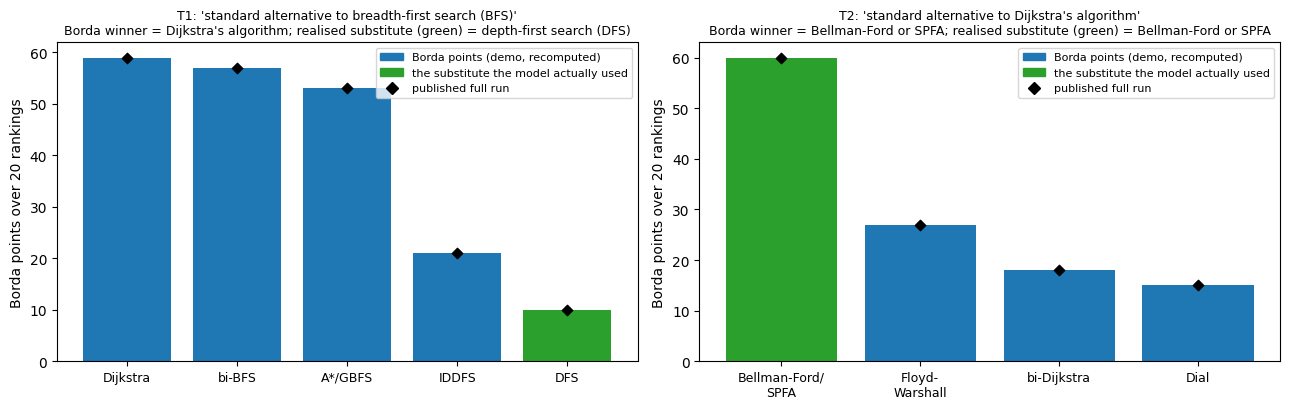

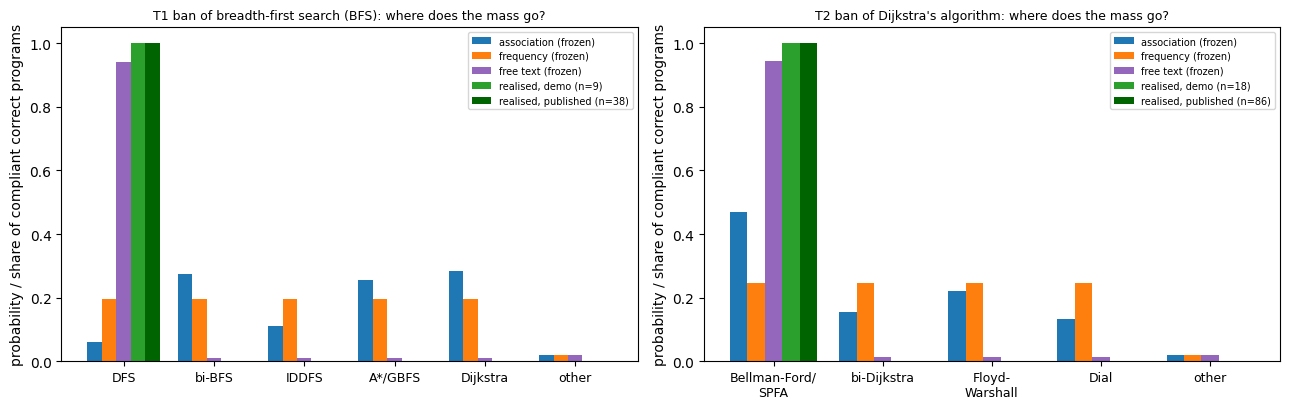


=== t1|ban:bfs ===   (programs replayed in the demo: 20; published arm: 100)
  quantity                                               demo              published
  programs with code                                       20                    100
  compliance (1 - recurrence)                           0.900                  0.900
  pass rate (hidden tests)                              0.550                  0.460
  compliant correct programs                                9                     38
  realised substitute                                     dfs                    dfs
  informative (pre-registered rule)                     False                   True
  pre-committed (audit)                                  True                   True
  assoc: nomination                                  dijkstra               dijkstra
  assoc: top-1 hit                                      0.000                  0.000
  assoc: mean log score                                -2.817           

In [34]:
contest_demo = json.loads((RESULTS_DIR / "contest.json").read_text())
table_demo = {e["event_id"]: e for e in json.loads((RESULTS_DIR / "event_table.json").read_text())}
ref = data["reference"]
table_ref = {e["event_id"]: e for e in ref["event_table"]}
contest_ref = {e["event_id"]: e for e in ref["contest"]["events"]}
contest_demo_ev = {e["event_id"]: e for e in contest_demo["events"]}
EVENTS = [("t1", "bfs", "dfs"), ("t2", "dijkstra", "bf_spfa")]
SHORT = {"bfs": "BFS", "dfs": "DFS", "bibfs": "bi-BFS", "iddfs": "IDDFS", "astar_gbfs": "A*/GBFS", "dijkstra": "Dijkstra",
         "bf_spfa": "Bellman-Ford/\nSPFA", "bidijkstra": "bi-Dijkstra", "floyd": "Floyd-\nWarshall", "dial": "Dial",
         OTHER: "other"}

# ---- Figure 1: association maps (Borda points), demo vs published ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (task, x, realised) in zip(axes, EVENTS):
    q, refm = assoc_demo["qwen"][task][x], ref["association_maps"][task][x]
    ys = sorted(q["borda_points"], key=lambda y: -q["borda_points"][y])
    cols = ["tab:green" if y == realised else "tab:blue" for y in ys]
    ax.bar(range(len(ys)), [q["borda_points"][y] for y in ys], color=cols)
    ax.scatter(range(len(ys)), [refm["borda_points"][y] for y in ys], color="black", zorder=3, marker="D", s=28)
    ax.set_xticks(range(len(ys)))
    ax.set_xticklabels([SHORT[y] for y in ys], fontsize=9)
    ax.set_title(f"{task.upper()}: 'standard alternative to {display(task, x)}'\nBorda winner = "
                 f"{display(task, q['borda_winner'])}; realised substitute (green) = {display(task, realised)}",
                 fontsize=9)
    ax.set_ylabel("Borda points over 20 rankings")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="tab:blue"), plt.Rectangle((0, 0), 1, 1, color="tab:green"),
                       plt.Line2D([], [], color="black", marker="D", linestyle="")],
              labels=["Borda points (demo, recomputed)", "the substitute the model actually used",
                      "published full run"], fontsize=8)
plt.tight_layout()
plt.show()

# ---- Figure 2: frozen forecasts vs realised substitute ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (task, x, realised) in zip(axes, EVENTS):
    eid = f"{task}|ban:{x}"
    pred = json.loads((PRED_DIR / f"{task}_single_bans.json").read_text())["events"][f"ban:{x}"]
    S = pred["survivors"]
    keys = S + [OTHER]
    rd, rr = table_demo[eid], table_ref[eid]
    nd = max(1, rd["n_compliant"])
    series = [("association (frozen)", [pred["composed"]["assoc"][y] for y in keys], "tab:blue"),
              ("frequency (frozen)", [pred["composed"]["freq"][y] for y in keys], "tab:orange"),
              ("free text (frozen)", [pred["composed"]["freetext"][y] for y in keys], "tab:purple"),
              (f"realised, demo (n={rd['n_compliant']})", [rd["realised_counts"].get(y, 0) / nd for y in keys],
               "tab:green"),
              (f"realised, published (n={rr['n_compliant']})",
               [rr["realised_counts"].get(y, 0) / max(1, rr["n_compliant"]) for y in keys], "darkgreen")]
    w = 0.16
    for i, (lab_, vals, col) in enumerate(series):
        ax.bar(np.arange(len(keys)) + (i - 2) * w, vals, width=w, color=col, label=lab_)
    ax.set_xticks(range(len(keys)))
    ax.set_xticklabels([SHORT[y] for y in keys], fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("probability / share of compliant correct programs")
    ax.set_title(f"{task.upper()} ban of {display(task, x)}: where does the mass go?", fontsize=9)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# ---- Table: demo vs published ----
def _fmt(v):
    if isinstance(v, float):
        return f"{v:.3f}"
    if isinstance(v, list):
        return f"tie of {len(v)}" if len(v) > 1 else str(v[0])
    return str(v)

for task, x, realised in EVENTS:
    eid = f"{task}|ban:{x}"
    rd, rr = table_demo[eid], table_ref[eid]
    cd, cr = contest_demo_ev.get(eid), contest_ref[eid]
    print(f"\n=== {eid} ===   (programs replayed in the demo: {rd['n_code']}; published arm: {rr['n_code']})")
    rows_ = [("programs with code", rd["n_code"], rr["n_code"]),
             ("compliance (1 - recurrence)", rd["compliance"], rr["compliance"]),
             ("pass rate (hidden tests)", rd["pass_rate"], rr["pass_rate"]),
             ("compliant correct programs", rd["n_compliant"], rr["n_compliant"]),
             ("realised substitute", rd["realised_mode"], rr["realised_mode"]),
             ("informative (pre-registered rule)", rd["informative"], rr["informative"]),
             ("pre-committed (audit)", rd["pre_committed"], rr["pre_committed"])]
    for name in ("assoc", "freq", "freetext"):
        rows_.append((f"{name}: nomination", rd["nominations"][name], rr["nominations"][name]))
        if cd:
            rows_.append((f"{name}: top-1 hit", cd["per_predictor"][name]["top1_hit"],
                          cr["per_predictor"][name]["top1_hit"]))
            rows_.append((f"{name}: mean log score", cd["per_predictor"][name]["log_score"],
                          cr["per_predictor"][name]["log_score"]))
    if cd:
        rows_.append(("paired log score, assoc - freq", cd["paired_assoc_minus_freq"]["mean"],
                      cr["paired_assoc_minus_freq"]["mean"]))
    print(f"  {'quantity':36s} {'demo':>22s} {'published':>22s}")
    for name, a, b in rows_:
        print(f"  {name:36s} {_fmt(a):>22s} {_fmt(b):>22s}")

pooled_ref = ref["contest"]["pooled_assoc_minus_freq"]
pooled_demo = contest_demo["strata"]["all_informative"]["pooled_assoc_minus_freq"]
print(f"\nPooled over the 2 events: association wins {pooled_demo['assoc_wins']}/{pooled_demo['assoc_wins_of']} "
      f"(published {pooled_ref['assoc_wins']}/{pooled_ref['assoc_wins_of']}); mean paired difference "
      f"{pooled_demo['mean_paired_diff']:.3f} nats/sample (published {pooled_ref['mean_paired_diff']:.3f})")

### Re-derivation checks and the published findings beyond this demo

In [35]:
prompts_ok = sha256_file(PROMPT_DIR / "conditions.json") == data["reference"]["commitments_log"][0]["sha"]
pre = read_jsonl(RAW_PREBAN) + read_jsonl(RAW_BANS)
lab_rows = [r for r in read_jsonl(LABELLED) if r["code"] is not None]
rec_lab = [RECORDED_LABELS[row_id(r)] for r in lab_rows]
assoc_ok = all(assoc_demo["qwen"][t][x]["borda_points"] == data["reference"]["association_maps"][t][x]["borda_points"]
               for t, x, _ in EVENTS)
frozen_ok = all(max(abs(json.loads((PRED_DIR / f"{t}_single_bans.json").read_text())["events"][f"ban:{x}"]["composed"]
                        [p][y] - data["reference"]["frozen_predictions"][f"{t}|ban:{x}"]["composed"][p][y])
                    for y in data["reference"]["frozen_predictions"][f"{t}|ban:{x}"]["composed"][p]) < 1e-12
                for t, x, _ in EVENTS for p in ("assoc", "freq"))
checks = {
    "prompts/conditions.json byte-identical to the frozen file (sha256)": prompts_ok,
    "every replayed row's per-request seed re-derived": all(r["seed"] == RECORDED[r["req_id"]][0]["seed"] for r in pre),
    "prompt token counts under the Qwen3 chat template match the run": all(
        r["n_prompt_tokens"] == RECORDED[r["req_id"]][0]["n_prompt_tokens"] for r in pre),
    "extracted code sha256 matches the run": all(r["code_sha256"] == q["code_sha256"] for r, q in zip(lab_rows, rec_lab)),
    "recomputed AST labels match the run": all(r["ast_label"] == q["ast_label"] for r, q in zip(lab_rows, rec_lab)),
    "combined labels match the run": all(r["label"] == q["label"] for r, q in zip(lab_rows, rec_lab)),
    "Borda points identical to the published association maps": assoc_ok,
    "frozen assoc/freq forecasts identical to the published frozen predictions": frozen_ok,
    "this run's commitments.log hash chain valid": verify_chain()[0],
    "modal-ban predictions committed before their arms were generated": all(
        table_demo[f"{t}|ban:{x}"]["pre_committed"] for t, x, _ in EVENTS),
}
for k, v in checks.items():
    print(f"  [{'OK' if v else 'MISMATCH'}] {k}")

print("\nPublished full-run findings that this demo does not recompute:")
for e in ref["event_table"]:
    if e["kind"] == "succession":
        dr = next(d for d in ref["disguised_recurrence"] if d["event_id"] == e["event_id"])
        print(f"  {e['event_id']}: banned {e['banned']} -> compliance {e['compliance']:.2f}, compliant correct "
              f"{e['n_compliant']}; {dr['recurrent_without_name']}/{dr['n_recurrent']} recurrent programs never "
              f"name the banned algorithm (descriptors {dr['descriptor_counts']})")
print("  mention twins (share of the named mode, mention minus baseline, percentage points):")
for k, v in ref["mention_effects"].items():
    if isinstance(v, dict) and v["share_baseline"] < 0.5:  # (skips the two list-all-vs-baseline JS summaries)
        print(f"    {k:16s} {v['mention_minus_baseline_pp']:+6.1f} pp  (ban arm share {v['share_ban']:.2f})")
print("  labeller gate (evaluation gold):", {k: round(v, 3) if isinstance(v, float) else v
                                            for k, v in ref["labeller_gate_eval_metrics"].items()
                                            if not isinstance(v, (dict, list))}, "| gate_passed =", ref["gate_passed"])

  [OK] prompts/conditions.json byte-identical to the frozen file (sha256)
  [OK] every replayed row's per-request seed re-derived
  [OK] prompt token counts under the Qwen3 chat template match the run
  [OK] extracted code sha256 matches the run
  [OK] recomputed AST labels match the run
  [OK] combined labels match the run
  [OK] Borda points identical to the published association maps
  [OK] frozen assoc/freq forecasts identical to the published frozen predictions
  [OK] this run's commitments.log hash chain valid
  [OK] modal-ban predictions committed before their arms were generated

Published full-run findings that this demo does not recompute:
  t1|succession:2: banned ['bfs', 'dfs'] -> compliance 0.06, compliant correct 5; 41/94 recurrent programs never name the banned algorithm (descriptors {'backtracking': 20, 'queue_word': 16, 'bfs_word': 7, 'priority_queue_word': 2})
  t2|succession:2: banned ['dijkstra', 'bf_spfa'] -> compliance 0.00, compliant correct 0; 58/100 recurrent p

## Takeaways

- **The prompts, seeds and frozen forecasts are re-derived exactly.** On this machine, from the raw outputs alone:
  the prompt file is byte-identical to the frozen one, the request seeds and chat-template token counts match the
  recorded rows, and the association (Borda) and typicality (frequency) forecasts equal the ones hash-committed before
  the ban arms were generated.
- **The outcome is the same on the demo subset.** The model obeys a ban of its modal algorithm, and the surviving
  mass lands on a single substitute: **DFS** on the grid task and **Bellman-Ford/SPFA** on the weighted task. A
  subset of 20 programs per arm already shows this.
- **The association map splits by task.** The Borda map ranks DFS *last* as a "standard alternative to BFS", so it
  misses on T1, while on T2 it nominates Bellman-Ford/SPFA and hits. The typicality ladder can only tie, because
  both baselines are fully collapsed. The model's own free-text answer ("the standard alternative to BFS is DFS")
  names the realised substitute in both events. The ranking instrument and free-text association diverge.
- **Not recomputed here** (published values are printed above):
  - **Double bans fail.** The model re-implements the banned mechanism under other names: "backtracking" DFS, or
    "BFS with pruning", which is SPFA.
  - **Mention twins act as strong recommendations, not placebos.**
  - **Labeller gate.** Its pre-registered targets were not met: kappa runtime-vs-AST 0.75, runtime vs adjudicated
    0.84, combined label 0.97.

All numbers are descriptive: two tasks and two informative events cannot support an inferential claim.